## Preparing the GPS Data for Analysis

In [12]:
import math
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib as mpl
import contextily as ctx
import pandas as pd

### 1 Flux Measurement Campaign

For this campaign, the following data points and transects in the dataset are identified:
1. GPS_Auto_XXXXXX: continuous measurements of the boat trajectory during the experiment
2. GPSXXXXXX: discrete measurements of the position of the measurement equipment and auxiliary materials
    - GPS000001 is the eastern end of the measurement frame
    - GPS000002 is the western end of the measurement frame
    - GPS000003 is the flagpole at the instruments
    - GPS000004 is the flagpole more in the port
    - GPS000005 is the flagpole more towards the sea

**1.1 Loading the Data**

In [13]:
file_path = r"Pruebas_DELFT_20261002.txt"
# Use the 20260926 filename here if that is the actual file you have.

columns = [
    "point_id",
    "date",
    "time",
    "easting",
    "northing",
    "ellipsoidal_height",
    "geoid_separation",
    "cq_3d",
]

gps = pd.read_csv(
    file_path,
    sep=r"\s+",
    skiprows=1,          # skip the descriptive header
    names=columns,
    dtype={
        "point_id": "string",
        "date": "string",
        "time": "string",
        "easting": "float64",
        "northing": "float64",
        "ellipsoidal_height": "float64",
        "geoid_separation": "float64",
        "cq_3d": "float64",
    },
)

gps["datetime"] = pd.to_datetime(
    gps["date"] + " " + gps["time"],
    format="%m/%d/%Y %H:%M:%S",
)
gps["datetime"] = gps["datetime"] - pd.Timedelta(hours=1)

gps = gps.drop(columns=["date", "time"])

# Determining actual elevations
gps['elevation'] = gps['ellipsoidal_height'] - gps['geoid_separation']

display(gps.head())

,point_id,easting,northing,ellipsoidal_height,geoid_separation,cq_3d,datetime,elevation
0,RTCM-Ref0017,806520.1897,2.343199e+06,-2.3498,-13.9267,NaN,2026-10-02 09:52:57,11.5769
1,GPS_Auto_000001,806503.2658,2.343120e+06,-14.1150,-13.9252,0.0171,2026-10-02 09:54:30,-0.1898
2,GPS_Auto_000002,806503.4395,2.343120e+06,-14.1546,-13.9252,0.0157,2026-10-02 09:54:31,-0.2294
3,GPS_Auto_000003,806503.7183,2.343120e+06,-14.0603,-13.9252,0.0158,2026-10-02 09:54:32,-0.1351
4,GPS_Auto_000004,806504.1683,2.343120e+06,-14.0468,-13.9252,0.0155,2026-10-02 09:54:33,-0.1216


**1.2 Calculating vessel speed**

In [14]:
# Extract the label from point_id
gps["trajectory"] = gps["point_id"].str.extract(
    r"^(GPS_Auto|GPS|PERFJAG|TEST|RTCM-Ref)",
    expand=False,
)

test = gps[gps["trajectory"] == "GPS_Auto"].sort_values("datetime")
gps_points = gps[gps["trajectory"] == "GPS"].sort_values("datetime")

# Calculate horizontal speed within each trajectory
ordered_gps = gps.sort_values(["trajectory", "datetime"])

delta_easting = ordered_gps.groupby("trajectory")["easting"].diff()
delta_northing = ordered_gps.groupby("trajectory")["northing"].diff()

delta_time = (
    ordered_gps.groupby("trajectory")["datetime"]
    .diff()
    .dt.total_seconds()
)

distance = np.hypot(delta_easting, delta_northing)

# Speed in metres per second
speed_m_s = distance / delta_time.where(delta_time > 0)

# Add the results to the original DataFrame order
gps["speed_m_s"] = speed_m_s.reindex(gps.index)
gps["speed_km_h"] = gps["speed_m_s"] * 3.6

display(
    gps[
        [
            "point_id",
            "trajectory",
            "datetime",
            "speed_m_s",
            "speed_km_h",
        ]
    ]
)


,point_id,trajectory,datetime,speed_m_s,speed_km_h
0,RTCM-Ref0017,RTCM-Ref,2026-10-02 09:52:57,NaN,NaN
1,GPS_Auto_000001,GPS_Auto,2026-10-02 09:54:30,NaN,NaN
2,GPS_Auto_000002,GPS_Auto,2026-10-02 09:54:31,0.328568,1.182845
3,GPS_Auto_000003,GPS_Auto,2026-10-02 09:54:32,0.368721,1.327395
4,GPS_Auto_000004,GPS_Auto,2026-10-02 09:54:33,0.475849,1.713056
...,...,...,...,...,...
6143,GPS0001,GPS,2026-10-02 11:43:30,NaN,NaN
6144,GPS0002,GPS,2026-10-02 11:44:11,0.021656,0.077960
6145,GPS0003,GPS,2026-10-02 11:44:36,0.018149,0.065336
6146,GPS0004,GPS,2026-10-02 11:45:17,0.076163,0.274187


**1.3 Plotting the entire experiment**

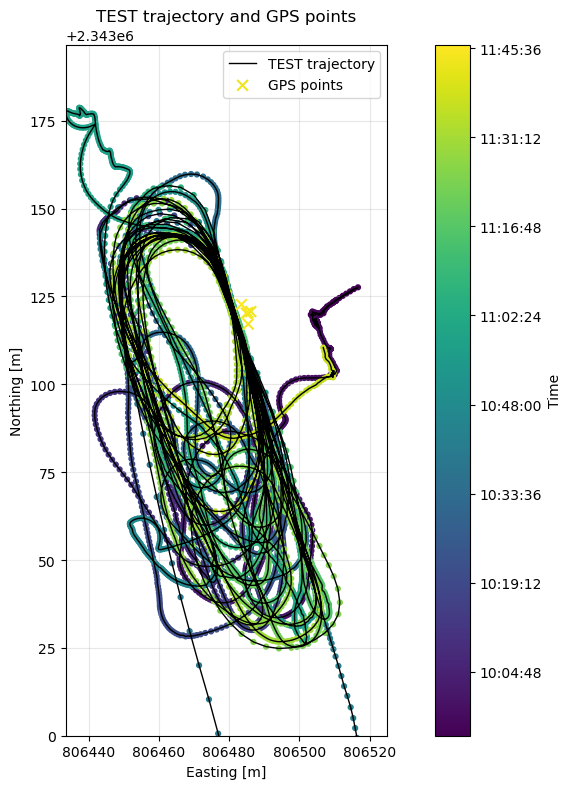

In [15]:
# Use one colour scale for both datasets
plot_data = pd.concat([test, gps_points])
time_values = mdates.date2num(plot_data["datetime"])

norm = mpl.colors.Normalize(
    time_values.min(),
    time_values.max(),
)
cmap = plt.colormaps["viridis"]

fig, ax = plt.subplots(figsize=(10, 8))

# TEST: chronological connected trajectory
ax.plot(
    test["easting"],
    test["northing"],
    color="black",
    linewidth=1,
    label="TEST trajectory",
)

ax.scatter(
    test["easting"],
    test["northing"],
    c=mdates.date2num(test["datetime"]),
    cmap=cmap,
    norm=norm,
    s=12,
)

# GPS: discrete points, not connected
ax.scatter(
    gps_points["easting"],
    gps_points["northing"],
    c=mdates.date2num(gps_points["datetime"]),
    cmap=cmap,
    norm=norm,
    marker="x",
    s=60,
    linewidths=1.5,
    label="GPS points",
)

ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("Easting [m]")
ax.set_ylabel("Northing [m]")
ax.set_title("TEST trajectory and GPS points")
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_ylim(2343000)
ax.set_xlim(np.min(test["easting"]), 806525)

scalar_map = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
scalar_map.set_array([])
colorbar = fig.colorbar(scalar_map, ax=ax)
colorbar.ax.yaxis.set_major_formatter(mdates.DateFormatter("%H:%M:%S"))
colorbar.set_label("Time")

plt.tight_layout()
plt.show()

**1.5 Plotting individual passages**

This is done by specifying the exact times of passage for each manoeuvre as recorded during the field experiment. The location at this specific time is interpolated, and a set time frame before and after that passage is plotted.

In [16]:
manoeuvres = {
    "B1-51": "10:07:17",
    "B1-52": "10:12:18",
    "B1-53": "10:15:24",
    "B1-54": "10:18:58",
    "B2-51": "10:23:29",
    "B2-52": "10:27:08",
    "B2-53": "10:31:06",
    "B2-54": "10:35:09",
    "B3-51": "10:38:24",
    "B3-52": "10:43:29",
    "B3-53": "10:48:18",
    "B3-54": "10:51:30",
    
    "B1-21": "11:05:02",
    "B1-22": "11:08:01",
    "B2-21": "11:10:58",
    "B2-22": "11:14:23",
    "A1-21": "11:18:17",
    "A1-22": "11:20:39",
    "A1-21": "11:23:01",
    "A2-22": "11:25:51",
    "A2-21": "11:28:17",

    "F-71":  "11:32:57", #time of 3rd pass 

    "B3-81": "11:00:24"

}

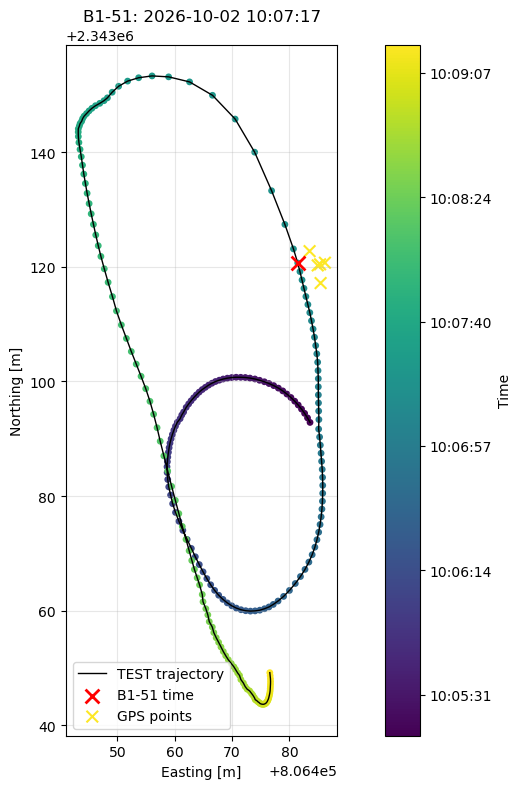

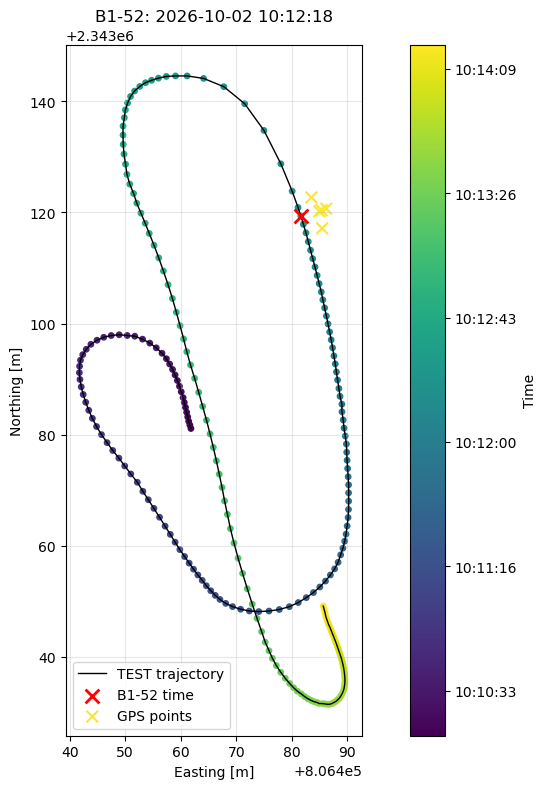

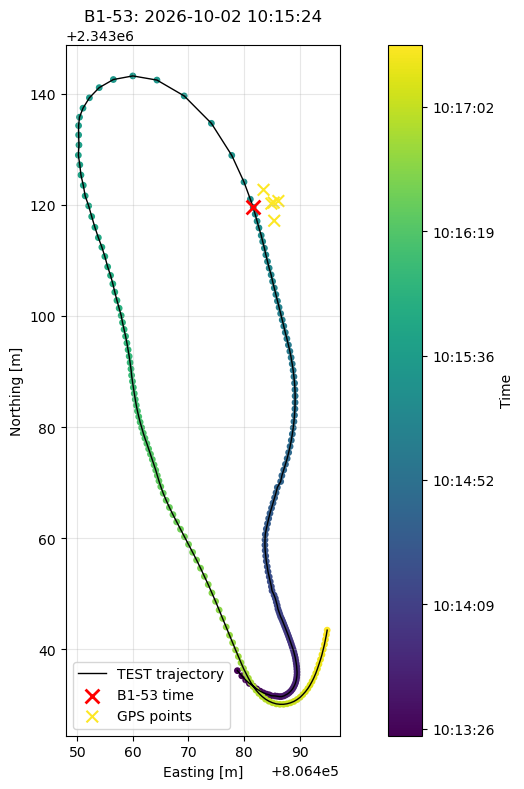

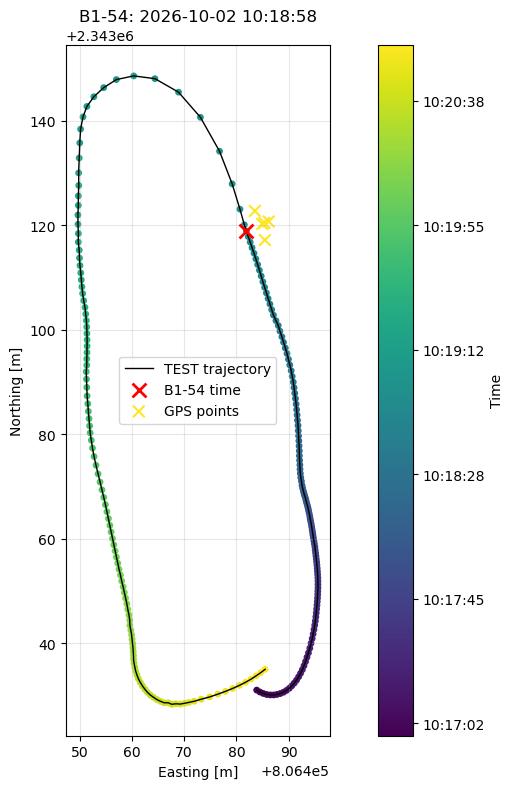

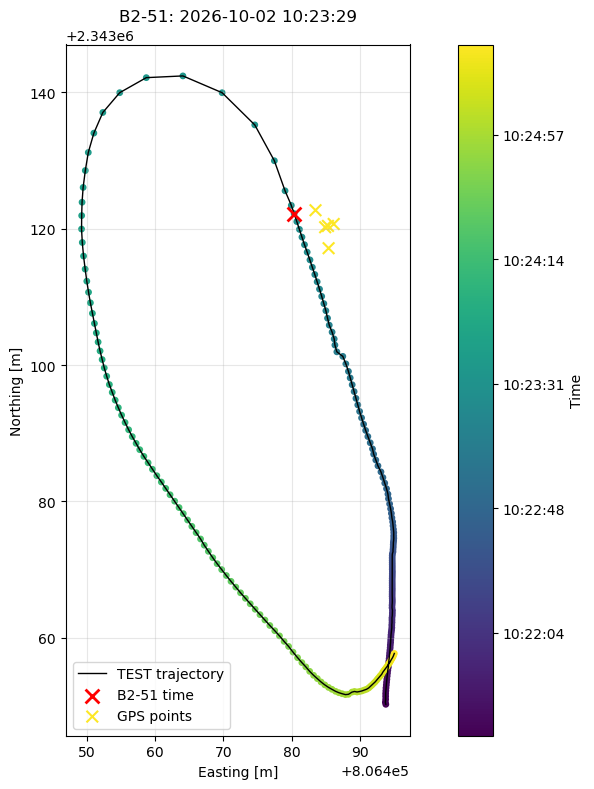

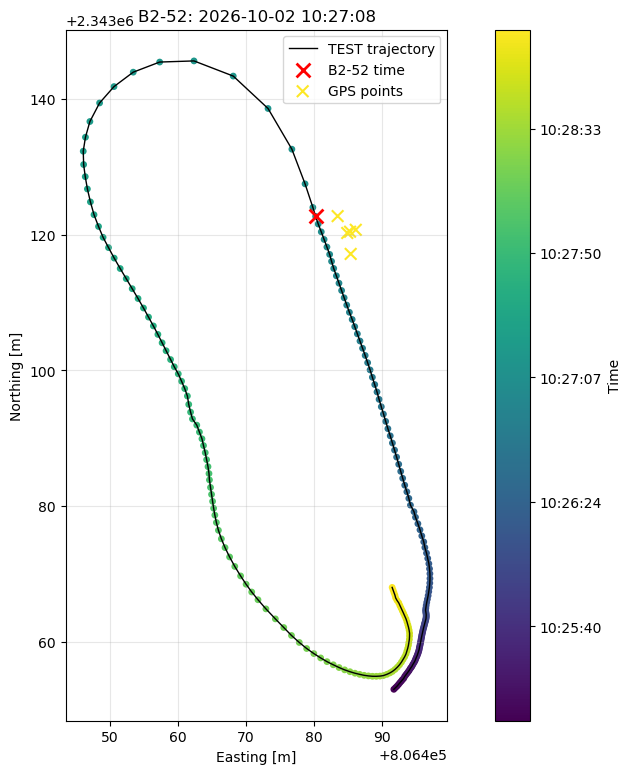

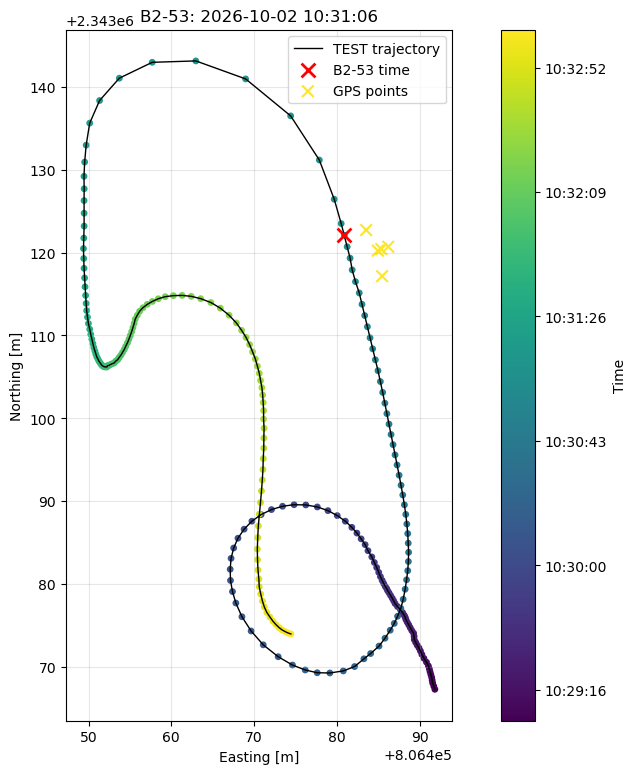

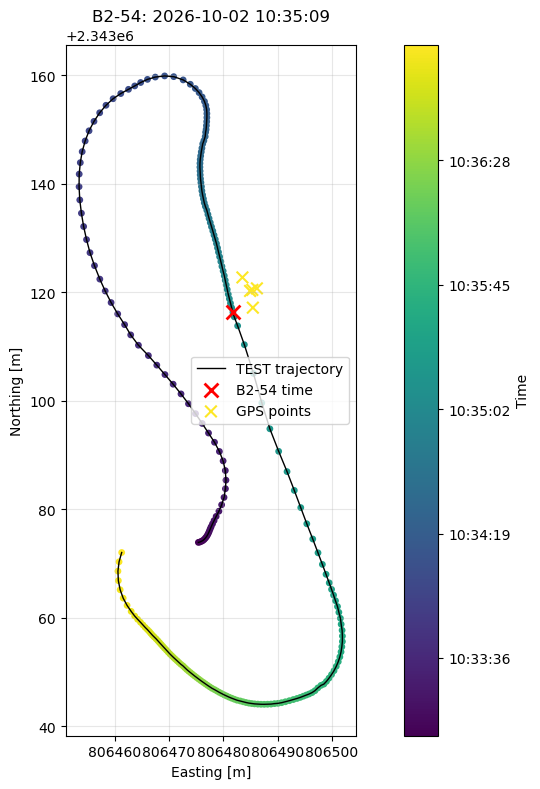

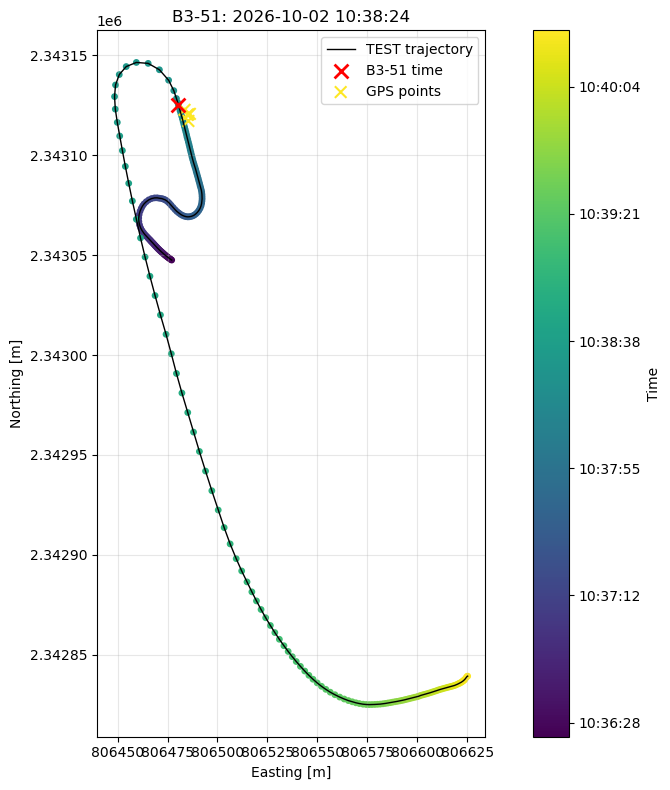

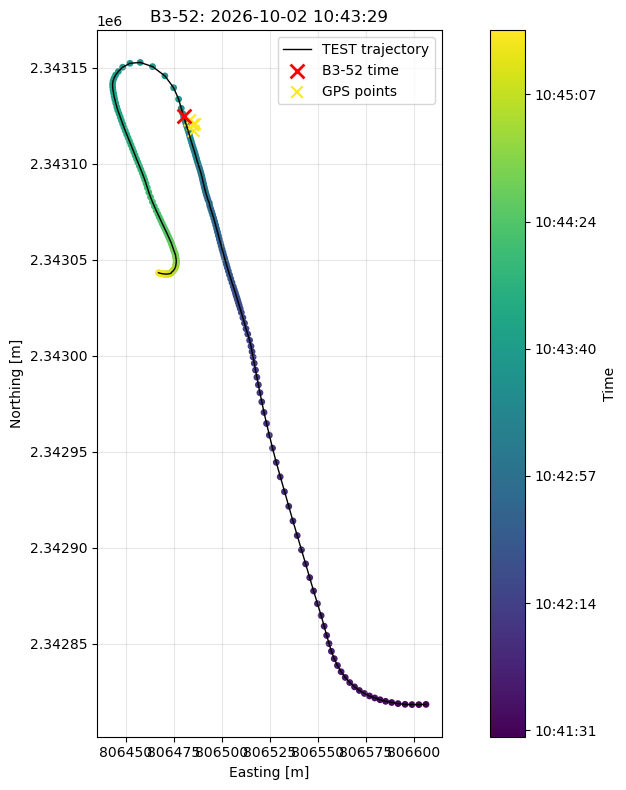

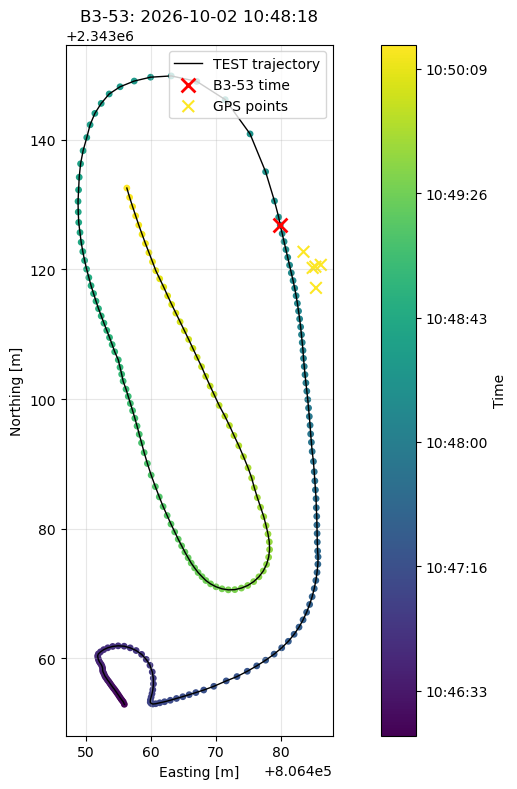

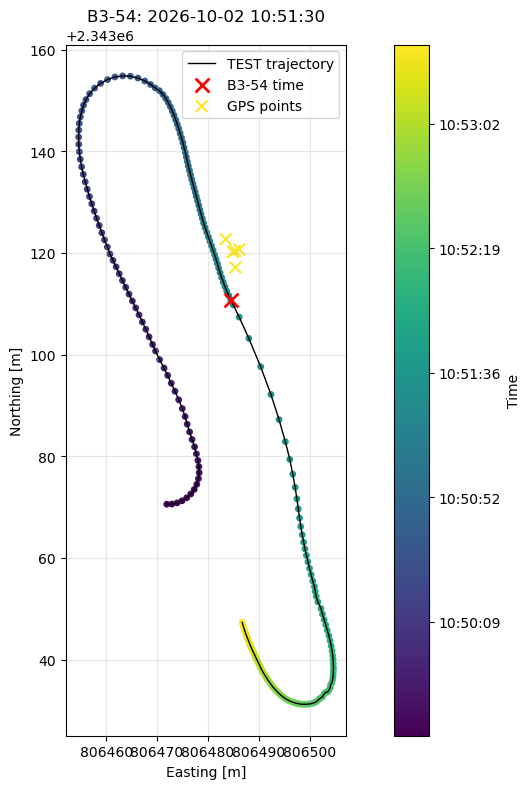

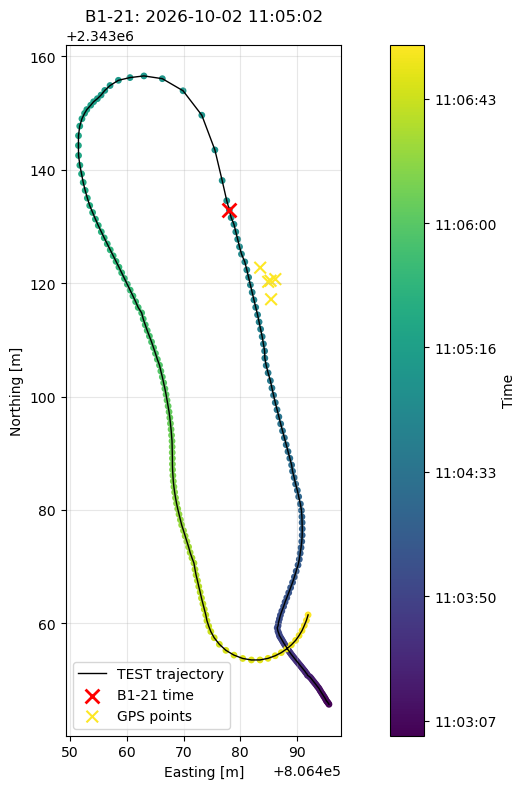

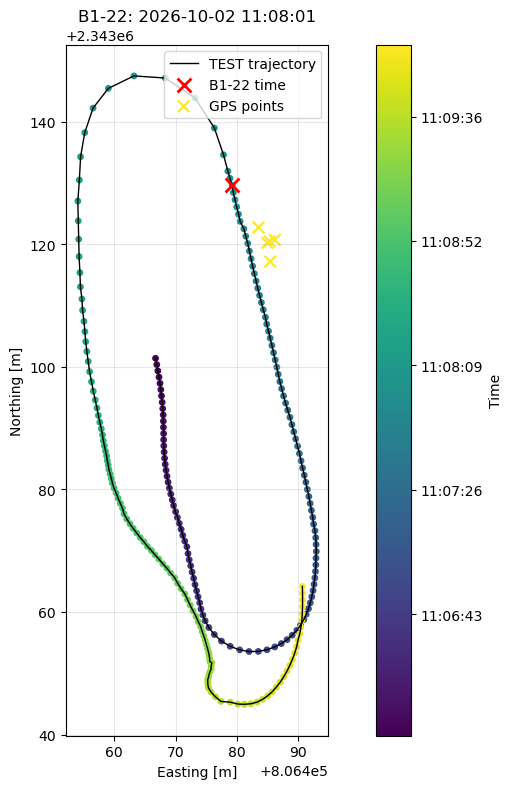

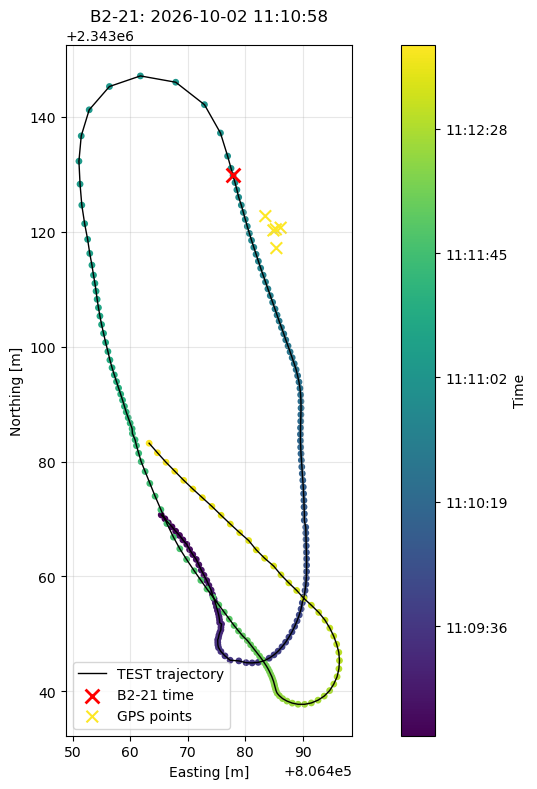

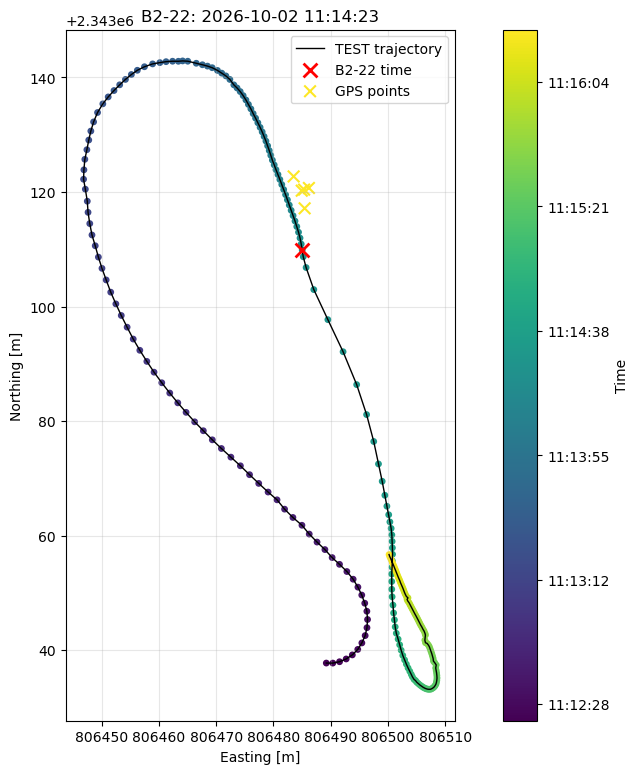

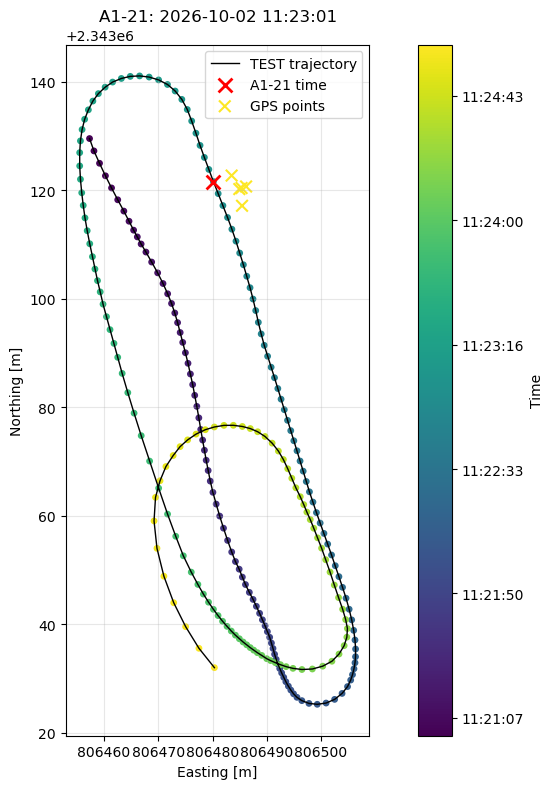

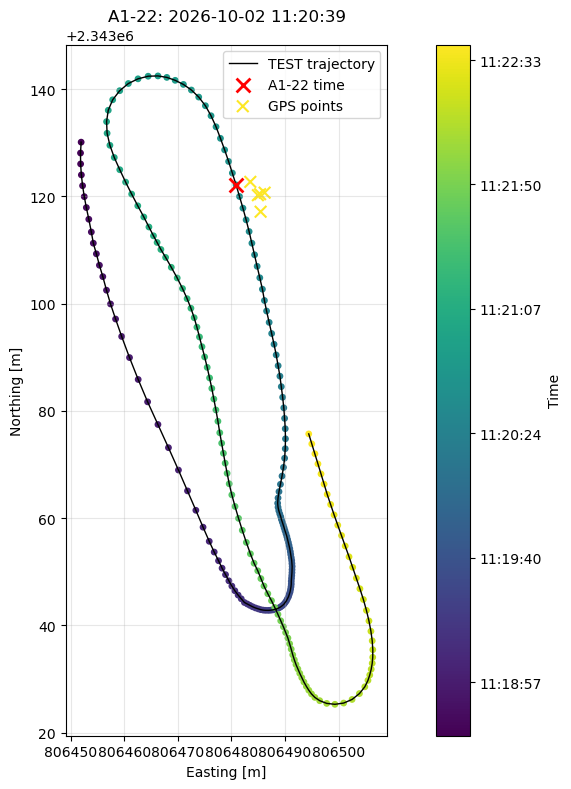

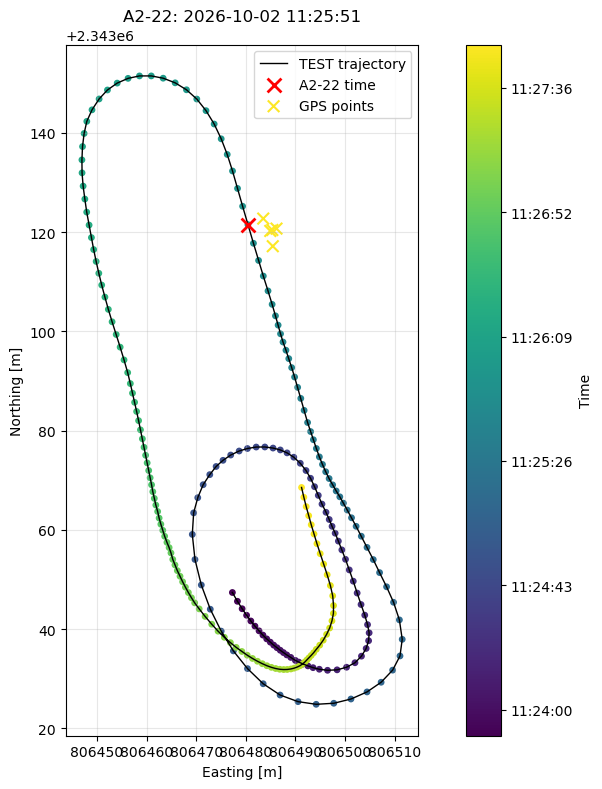

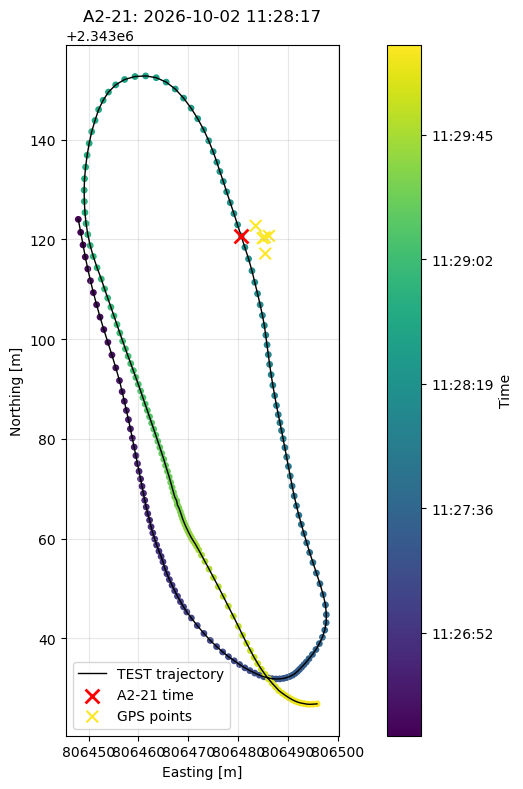

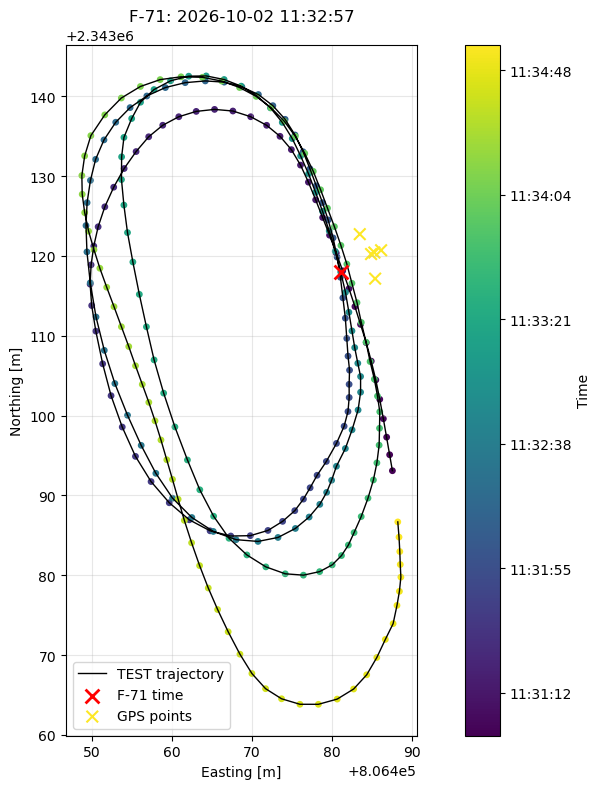

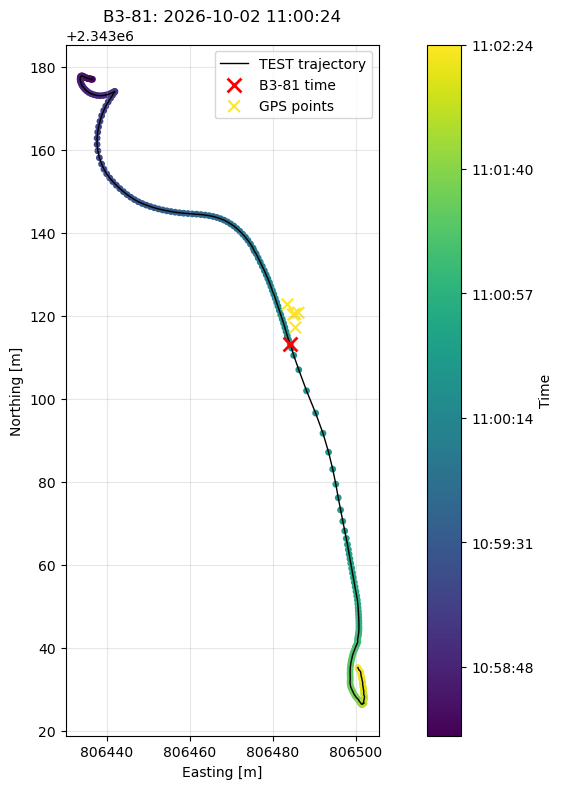

In [17]:
# Plotting individual manoeuvres

manoeuvre_date = "2026-10-02"

for manoeuvre_name, manoeuvre_time in manoeuvres.items():
    manoeuvre_datetime = pd.to_datetime(
        f"{manoeuvre_date} {manoeuvre_time}",
        format="%Y-%m-%d %H:%M:%S",
    )

    start_time = manoeuvre_datetime - pd.Timedelta(minutes=2)
    end_time = manoeuvre_datetime + pd.Timedelta(minutes=2)

    time_window = gps[
        gps["datetime"].between(start_time, end_time)
    ].copy()

    test_window = time_window[
        time_window["trajectory"] == "GPS_Auto"
    ].sort_values("datetime")

    if time_window.empty:
        print(f"No data found for {manoeuvre_name} at {manoeuvre_time}")
        continue

    time_values = mdates.date2num(time_window["datetime"])
    norm = mpl.colors.Normalize(
        time_values.min(),
        time_values.max(),
    )
    cmap = plt.colormaps["viridis"]

    fig, ax = plt.subplots(figsize=(10, 8))

    if not test_window.empty:
        ax.plot(
            test_window["easting"],
            test_window["northing"],
            color="black",
            linewidth=1,
            label="TEST trajectory",
        )

        ax.scatter(
            test_window["easting"],
            test_window["northing"],
            c=mdates.date2num(test_window["datetime"]),
            cmap=cmap,
            norm=norm,
            s=15,
        )

        # Interpolate the TEST position at the exact manoeuvre time.
        test_timestamps = test_window["datetime"].astype("int64")
        manoeuvre_timestamp = manoeuvre_datetime.value

        if (
            manoeuvre_timestamp >= test_timestamps.min()
            and manoeuvre_timestamp <= test_timestamps.max()
        ):
            manoeuvre_easting = np.interp(
                manoeuvre_timestamp,
                test_timestamps,
                test_window["easting"],
            )
            manoeuvre_northing = np.interp(
                manoeuvre_timestamp,
                test_timestamps,
                test_window["northing"],
            )

            ax.scatter(
                manoeuvre_easting,
                manoeuvre_northing,
                color="red",
                marker="x",
                s=100,
                linewidths=2,
                zorder=5,
                label=f"{manoeuvre_name} time",
            )

    # GPS measurements are discrete points and are not connected.
    ax.scatter(
        gps_points["easting"],
        gps_points["northing"],
        c=mdates.date2num(gps_points["datetime"]),
        cmap=cmap,
        norm=norm,
        marker="x",
        s=70,
        linewidths=1.5,
        label="GPS points",
        )

    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel("Easting [m]")
    ax.set_ylabel("Northing [m]")
    ax.set_title(
        f"{manoeuvre_name}: {manoeuvre_datetime:%Y-%m-%d %H:%M:%S}"
    )
    ax.legend()
    ax.grid(True, alpha=0.3)

    scalar_map = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
    scalar_map.set_array([])

    colorbar = fig.colorbar(scalar_map, ax=ax)
    colorbar.ax.yaxis.set_major_formatter(
        mdates.DateFormatter("%H:%M:%S")
    )
    colorbar.set_label("Time")

    plt.tight_layout()
    plt.show()

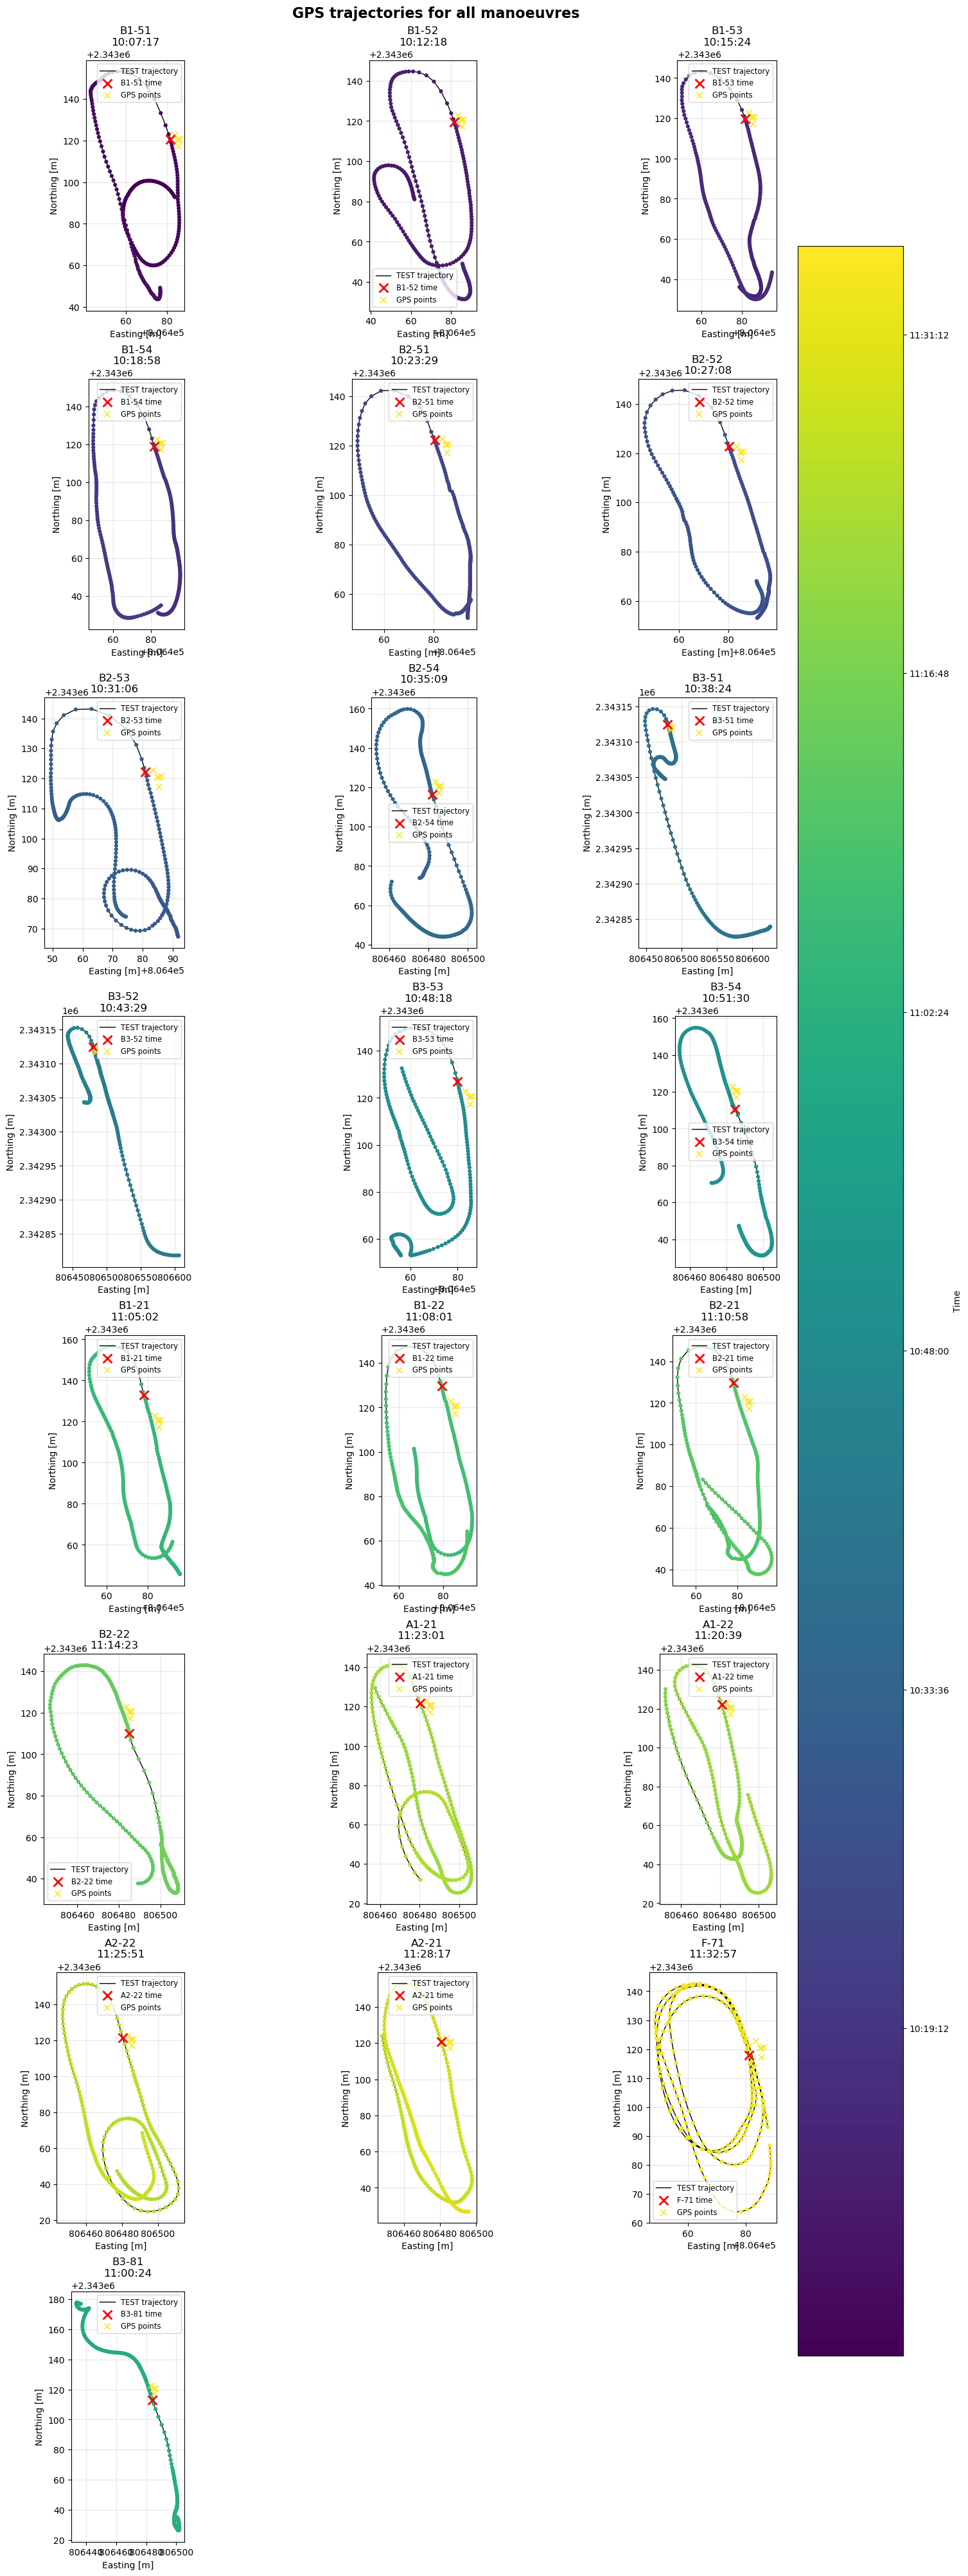

In [18]:
manoeuvre_date = "2026-10-02"

# Prepare the data for every manoeuvre first
manoeuvre_windows = []

for manoeuvre_name, manoeuvre_time in manoeuvres.items():
    manoeuvre_datetime = pd.to_datetime(
        f"{manoeuvre_date} {manoeuvre_time}",
        format="%Y-%m-%d %H:%M:%S",
    )

    start_time = manoeuvre_datetime - pd.Timedelta(minutes=2)
    end_time = manoeuvre_datetime + pd.Timedelta(minutes=2)

    time_window = gps[
        gps["datetime"].between(start_time, end_time)
    ].copy()

    if time_window.empty:
        print(f"No data found for {manoeuvre_name} at {manoeuvre_time}")
        continue

    test_window = time_window[
        time_window["trajectory"] == "GPS_Auto"
    ].sort_values("datetime")

    manoeuvre_windows.append(
        {
            "name": manoeuvre_name,
            "datetime": manoeuvre_datetime,
            "time_window": time_window,
            "test_window": test_window,
        }
    )

if not manoeuvre_windows:
    raise ValueError("No manoeuvre windows contain GPS data.")

# Use one common colour scale for all panels
all_time_values = np.concatenate(
    [
        mdates.date2num(window["time_window"]["datetime"])
        for window in manoeuvre_windows
    ]
)

norm = mpl.colors.Normalize(
    vmin=all_time_values.min(),
    vmax=all_time_values.max(),
)

cmap = plt.colormaps["viridis"]

# Three columns, with enough rows for all manoeuvres
ncols = 3
nrows = math.ceil(len(manoeuvre_windows) / ncols)

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(5.5 * ncols, 5 * nrows),
    squeeze=False,
    constrained_layout=True,
)

axes = axes.ravel()

for ax, window in zip(axes, manoeuvre_windows):
    manoeuvre_name = window["name"]
    manoeuvre_datetime = window["datetime"]
    test_window = window["test_window"]

    # TEST trajectory
    if not test_window.empty:
        ax.plot(
            test_window["easting"],
            test_window["northing"],
            color="black",
            linewidth=1,
            label="TEST trajectory",
            zorder=2,
        )

        ax.scatter(
            test_window["easting"],
            test_window["northing"],
            c=mdates.date2num(test_window["datetime"]),
            cmap=cmap,
            norm=norm,
            s=12,
            zorder=3,
        )

        # Interpolate TEST position at the exact manoeuvre time
        test_timestamps = test_window["datetime"].astype("int64")
        manoeuvre_timestamp = manoeuvre_datetime.value

        if (
            manoeuvre_timestamp >= test_timestamps.min()
            and manoeuvre_timestamp <= test_timestamps.max()
        ):
            manoeuvre_easting = np.interp(
                manoeuvre_timestamp,
                test_timestamps,
                test_window["easting"],
            )

            manoeuvre_northing = np.interp(
                manoeuvre_timestamp,
                test_timestamps,
                test_window["northing"],
            )

            ax.scatter(
                manoeuvre_easting,
                manoeuvre_northing,
                color="red",
                marker="x",
                s=100,
                linewidths=2,
                label=f"{manoeuvre_name} time",
                zorder=5,
            )

    # Discrete GPS measurements
    ax.scatter(
        gps_points["easting"],
        gps_points["northing"],
        c=mdates.date2num(gps_points["datetime"]),
        cmap=cmap,
        norm=norm,
        marker="x",
        s=45,
        linewidths=1.2,
        label="GPS points",
        zorder=4,
    )

    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel("Easting [m]")
    ax.set_ylabel("Northing [m]")
    ax.set_title(
        f"{manoeuvre_name}\n"
        f"{manoeuvre_datetime:%H:%M:%S}"
    )
    ax.grid(True, alpha=0.3)

    # Avoid repeating a large legend in every panel
    ax.legend(fontsize="small", loc="best")

# Hide unused axes in the final row
for ax in axes[len(manoeuvre_windows):]:
    ax.set_visible(False)

# One colourbar for the complete figure
scalar_map = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
scalar_map.set_array([])

colorbar = fig.colorbar(
    scalar_map,
    ax=axes[:len(manoeuvre_windows)].tolist(),
    shrink=0.85,
    pad=0.02,
)

colorbar.ax.yaxis.set_major_formatter(
    mdates.DateFormatter("%H:%M:%S")
)
colorbar.set_label("Time")

fig.suptitle(
    "GPS trajectories for all manoeuvres",
    fontsize=16,
    fontweight="bold",
)

plt.show()

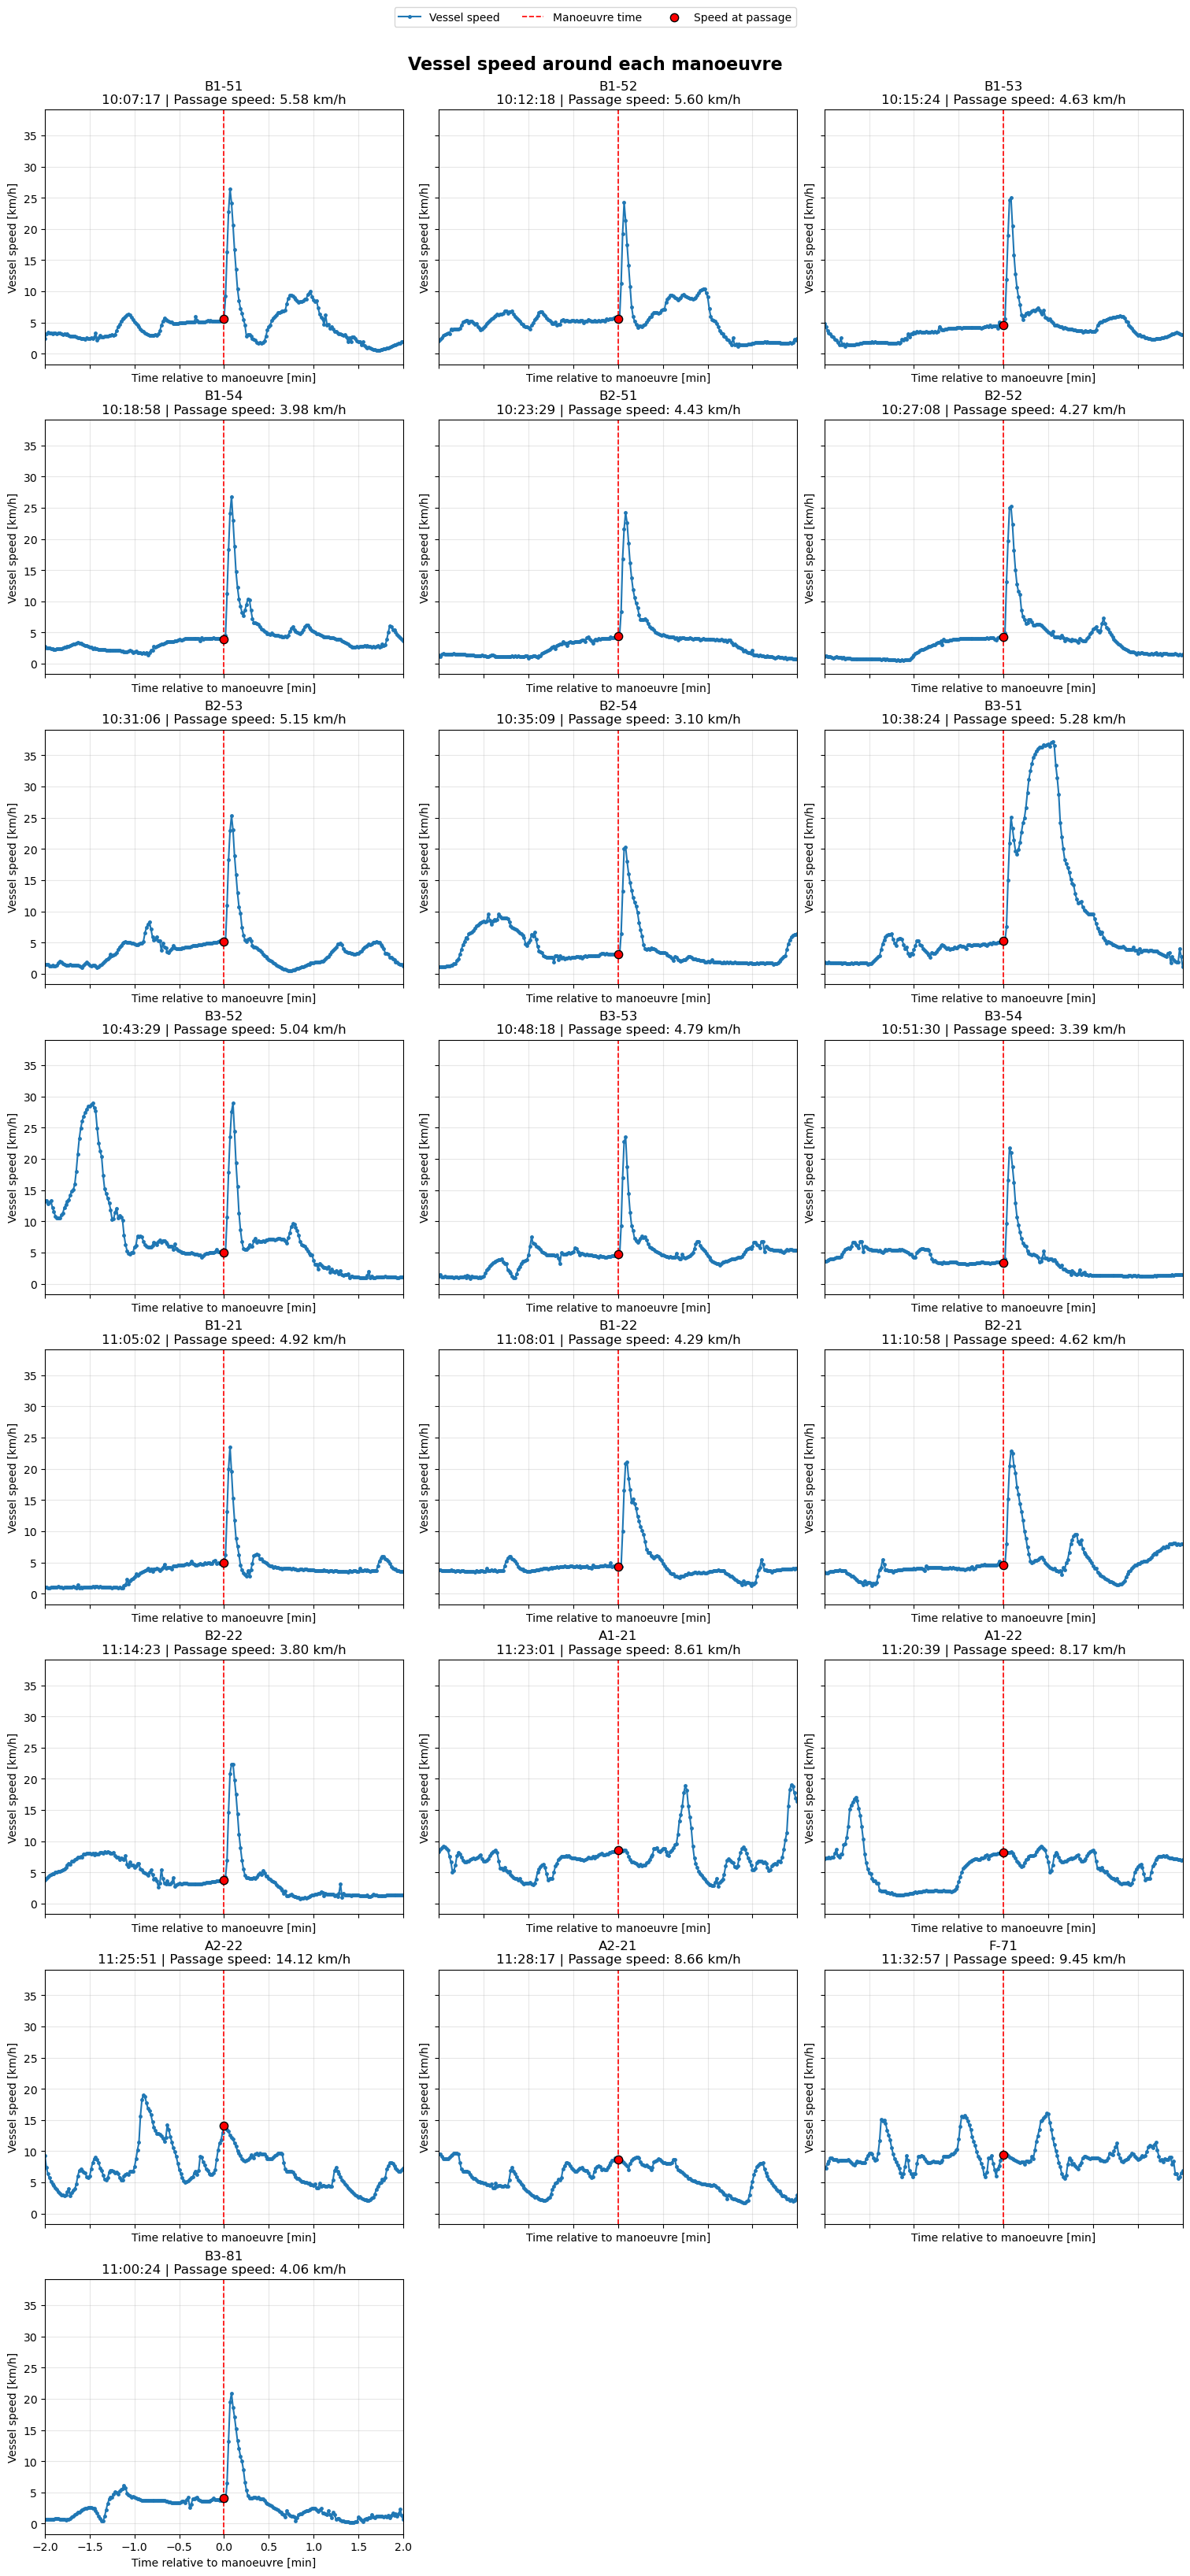

In [19]:
manoeuvre_date = "2026-10-02"

window_before = pd.Timedelta(minutes=2)
window_after = pd.Timedelta(minutes=2)

speed_windows = []

for manoeuvre_name, manoeuvre_time in manoeuvres.items():
    manoeuvre_datetime = pd.to_datetime(
        f"{manoeuvre_date} {manoeuvre_time}",
        format="%Y-%m-%d %H:%M:%S",
    )

    start_time = manoeuvre_datetime - window_before
    end_time = manoeuvre_datetime + window_after

    speed_window = gps[
        (gps["trajectory"] == "GPS_Auto")
        & gps["datetime"].between(start_time, end_time)
    ].copy()

    if speed_window.empty:
        print(f"No TEST speed data found for {manoeuvre_name}")
        continue

    speed_window = speed_window.sort_values("datetime")

    # Only valid speeds can be used for interpolation
    valid_speed = speed_window.dropna(
        subset=["speed_km_h"]
    ).copy()

    if valid_speed.empty:
        print(f"No valid speed data found for {manoeuvre_name}")
        continue

    # Time relative to the manoeuvre, in minutes
    speed_window["relative_time_min"] = (
        speed_window["datetime"] - manoeuvre_datetime
    ).dt.total_seconds() / 60

    # Time relative to the manoeuvre, in seconds
    relative_seconds = (
        valid_speed["datetime"] - manoeuvre_datetime
    ).dt.total_seconds()

    # Interpolate only if the passage is bracketed by valid data
    if relative_seconds.min() <= 0 <= relative_seconds.max():
        speed_at_passage = np.interp(
            0,
            relative_seconds.to_numpy(),
            valid_speed["speed_km_h"].to_numpy(),
        )
        speed_text = f"{speed_at_passage:.2f} km/h"
    else:
        speed_at_passage = np.nan
        speed_text = "unavailable"

    speed_windows.append(
        {
            "name": manoeuvre_name,
            "datetime": manoeuvre_datetime,
            "data": speed_window,
            "speed_at_passage": speed_at_passage,
            "speed_text": speed_text,
        }
    )

if not speed_windows:
    raise ValueError("No manoeuvre windows contain valid TEST speed data.")

# Configure the compact layout
ncols = 3
nrows = math.ceil(len(speed_windows) / ncols)

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(5 * ncols, 4 * nrows),
    sharex=True,
    sharey=True,
    squeeze=False,
    constrained_layout=True,
)

axes = axes.ravel()

for ax, window in zip(axes, speed_windows):
    speed_window = window["data"]
    speed_at_passage = window["speed_at_passage"]

    ax.plot(
        speed_window["relative_time_min"],
        speed_window["speed_km_h"],
        color="tab:blue",
        linewidth=1.5,
        marker="o",
        markersize=2.5,
        label="Vessel speed",
    )

    # Mark the passage time
    ax.axvline(
        0,
        color="red",
        linestyle="--",
        linewidth=1.2,
        label="Manoeuvre time",
    )

    # Mark the interpolated speed at passage
    if not np.isnan(speed_at_passage):
        ax.scatter(
            0,
            speed_at_passage,
            color="red",
            edgecolor="black",
            s=55,
            zorder=5,
            label="Speed at passage",
        )

    ax.set_xlim(-2, 2)
    ax.set_xlabel("Time relative to manoeuvre [min]")
    ax.set_ylabel("Vessel speed [km/h]")
    ax.set_title(
        f"{window['name']}\n"
        f"{window['datetime']:%H:%M:%S} | "
        f"Passage speed: {window['speed_text']}"
    )
    ax.grid(True, alpha=0.3)

# Hide unused axes in the last row
for ax in axes[len(speed_windows):]:
    ax.set_visible(False)

# Create one shared legend
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=3,
    bbox_to_anchor=(0.5, 1.02),
)

fig.suptitle(
    "Vessel speed around each manoeuvre",
    fontsize=16,
    fontweight="bold",
)

plt.show()

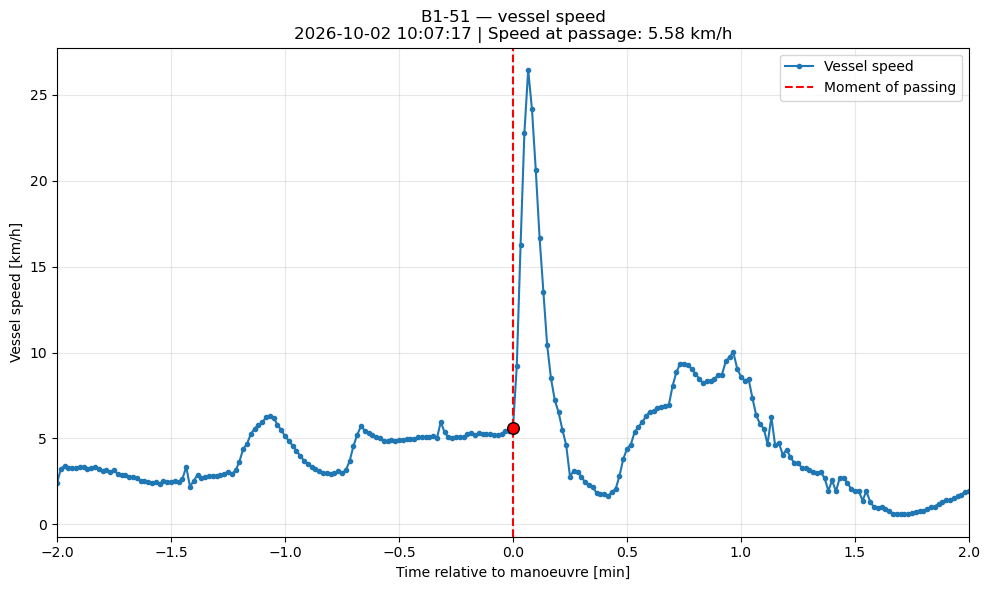

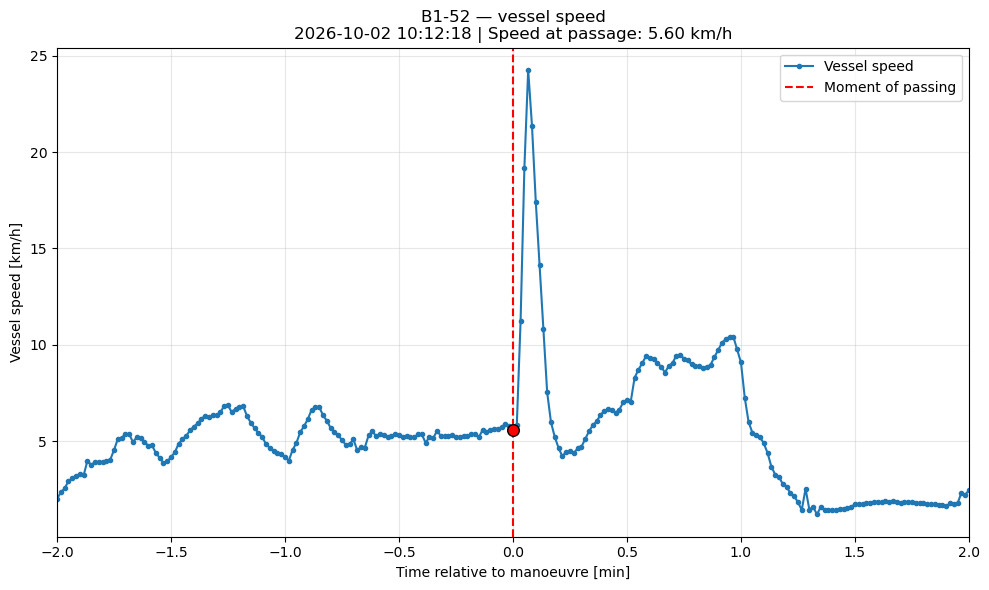

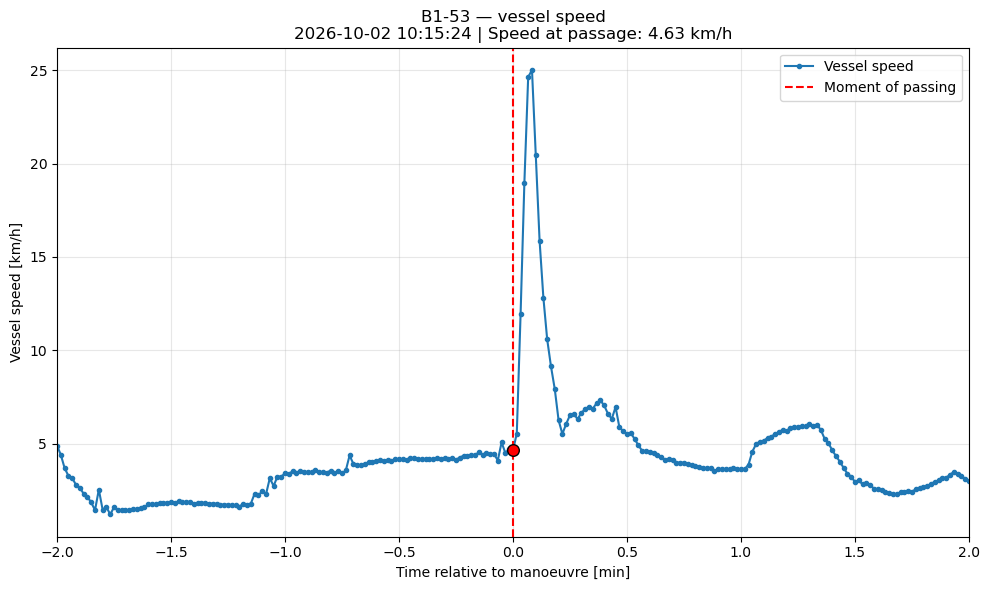

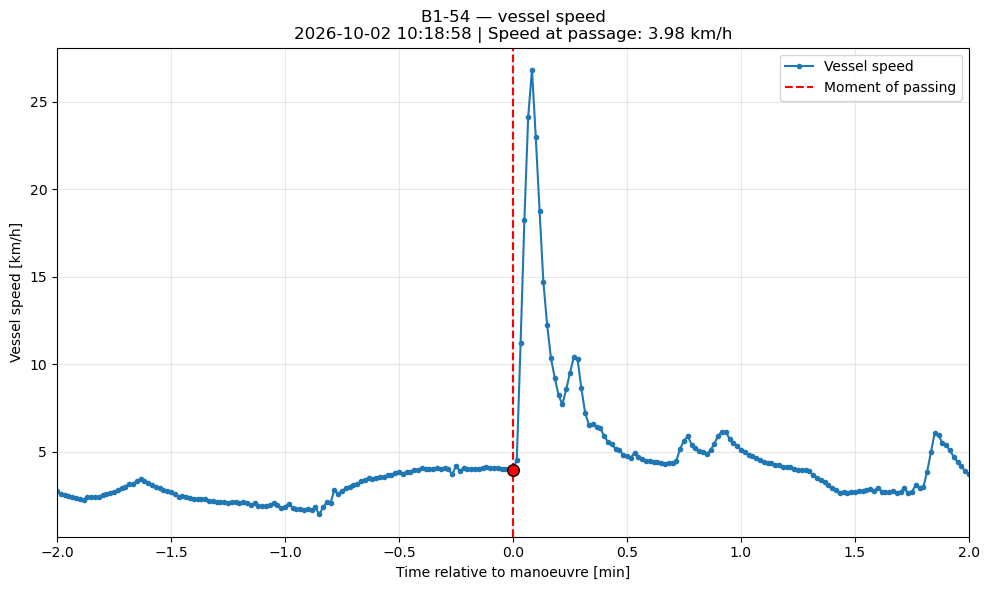

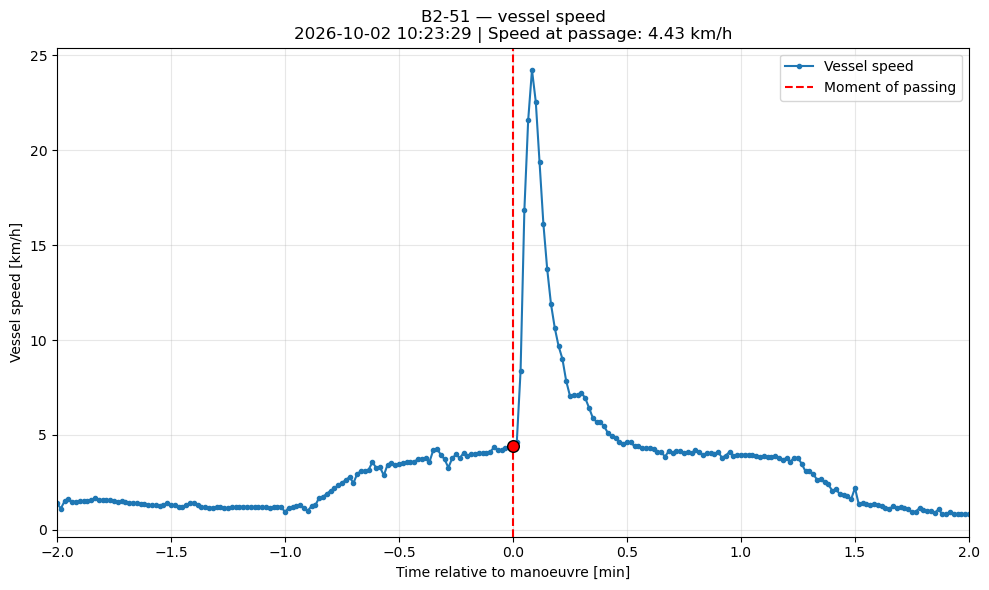

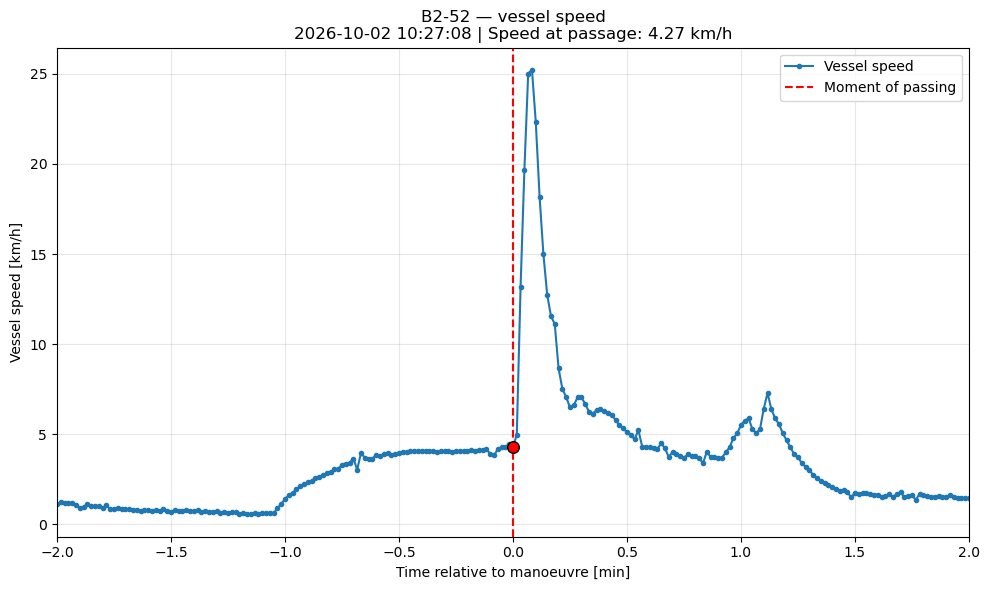

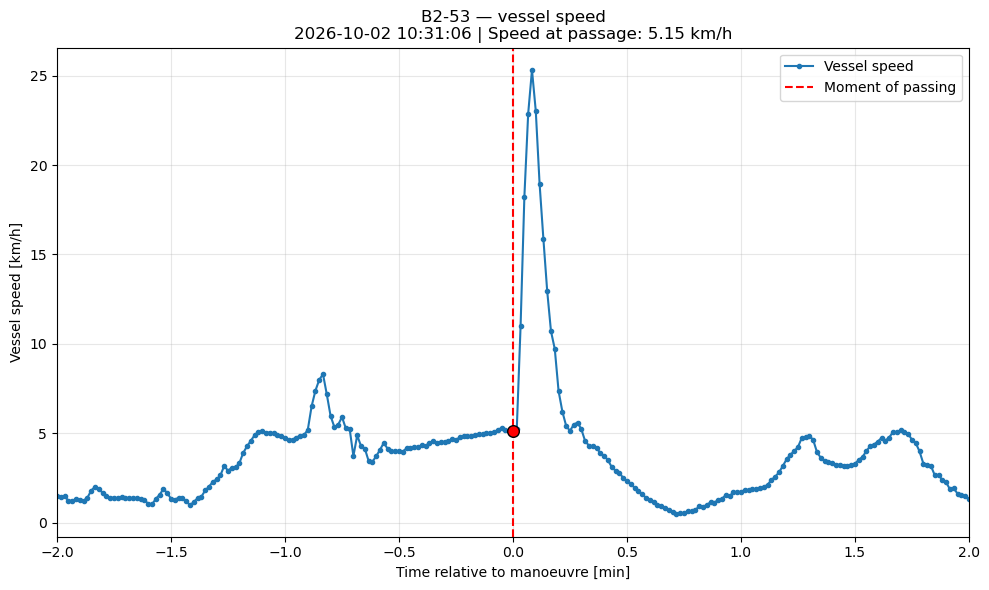

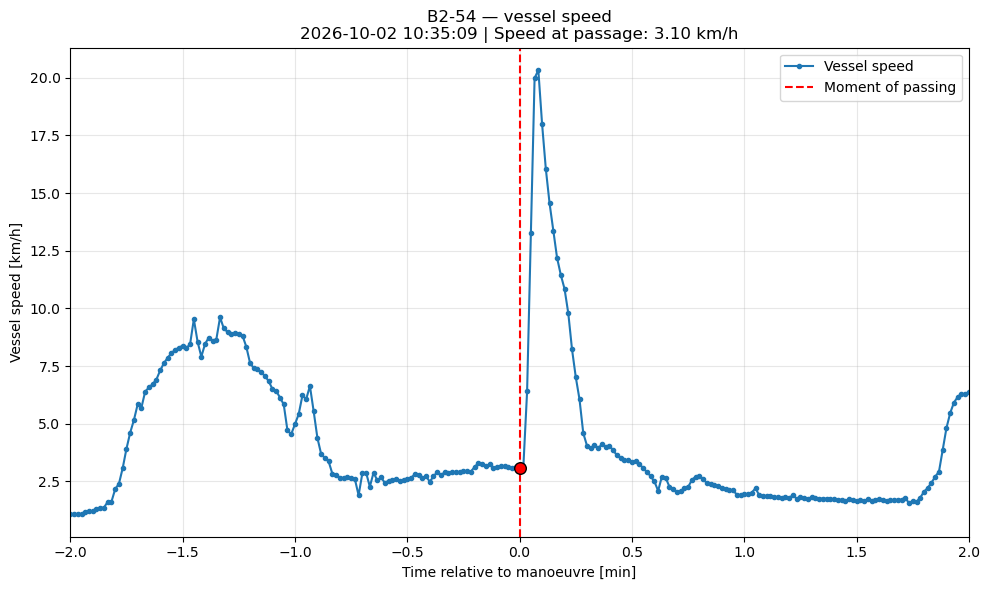

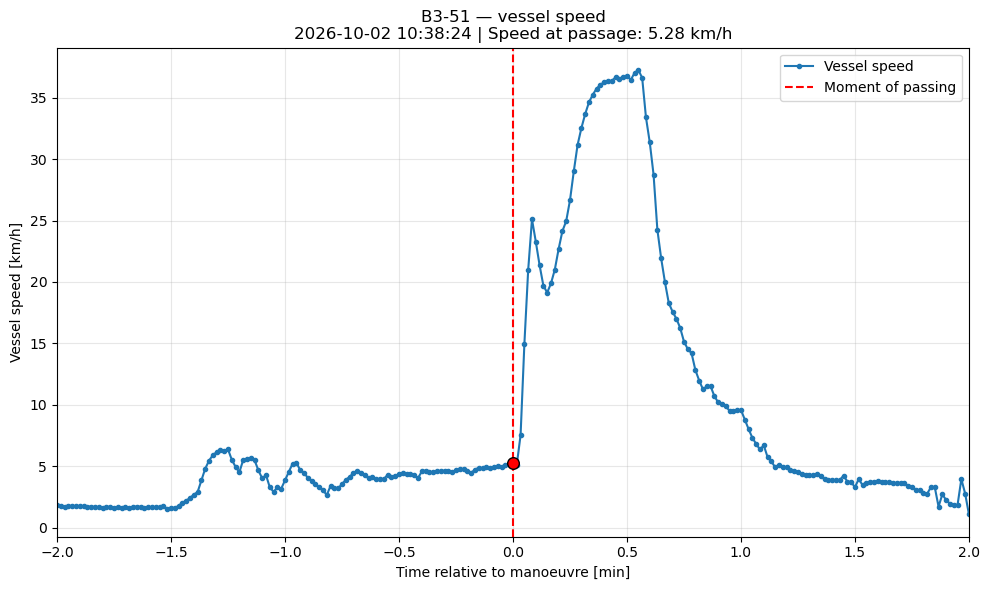

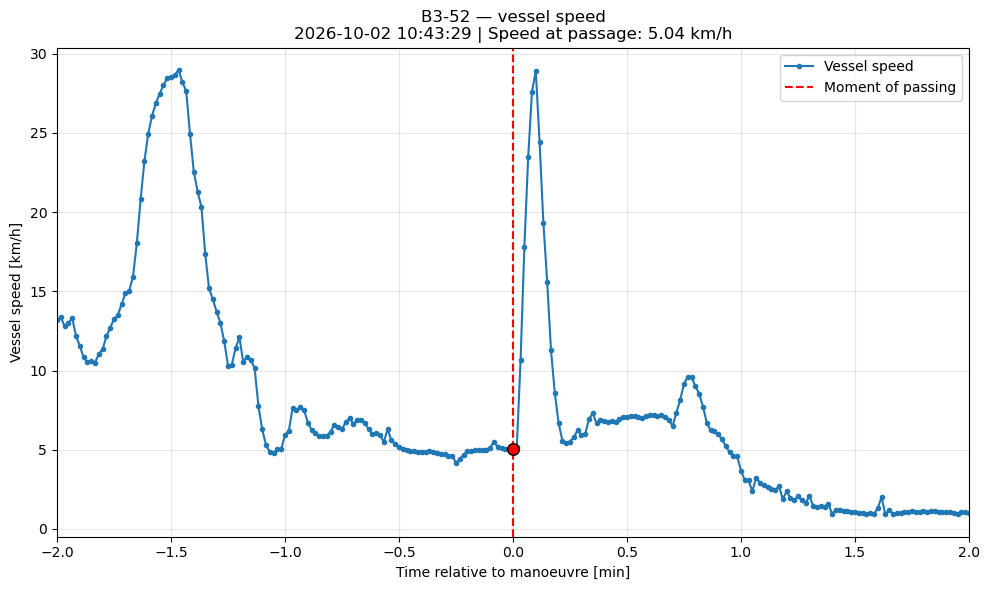

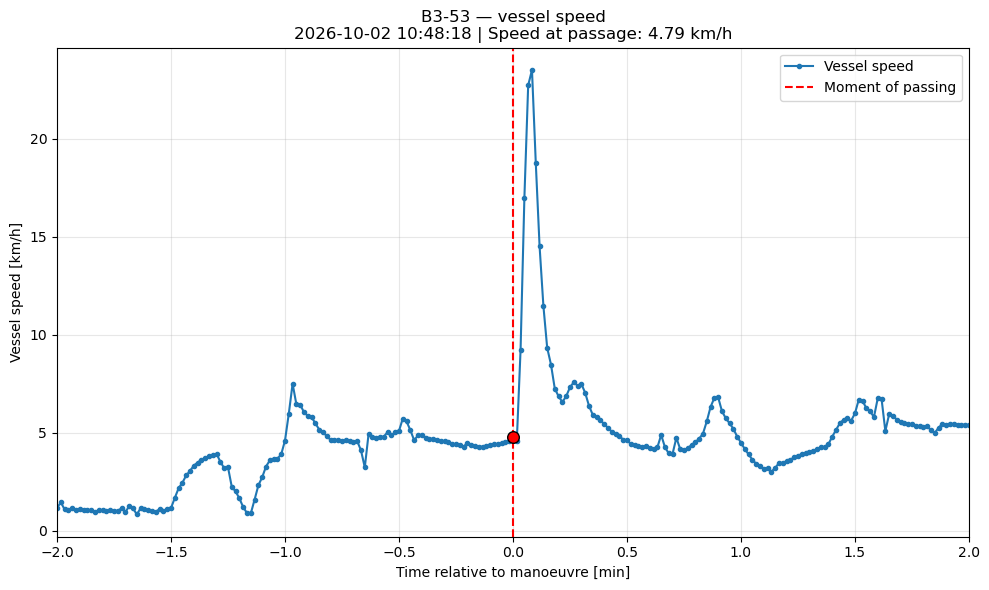

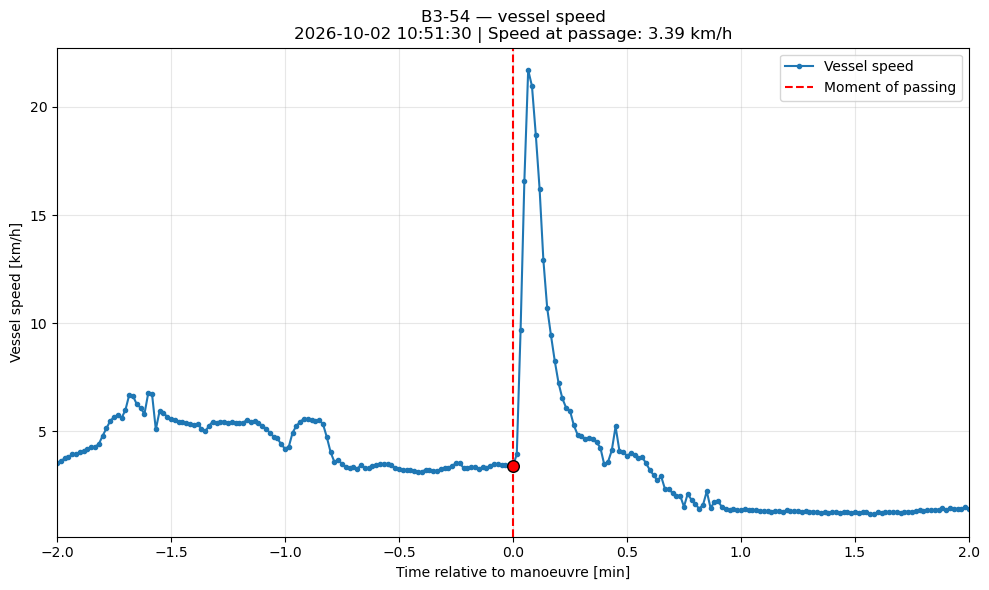

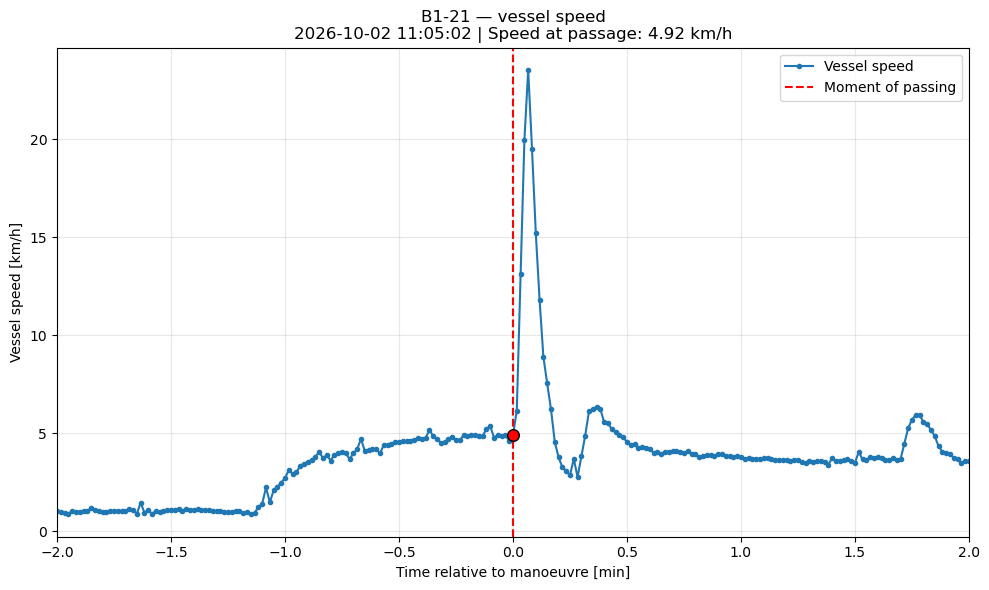

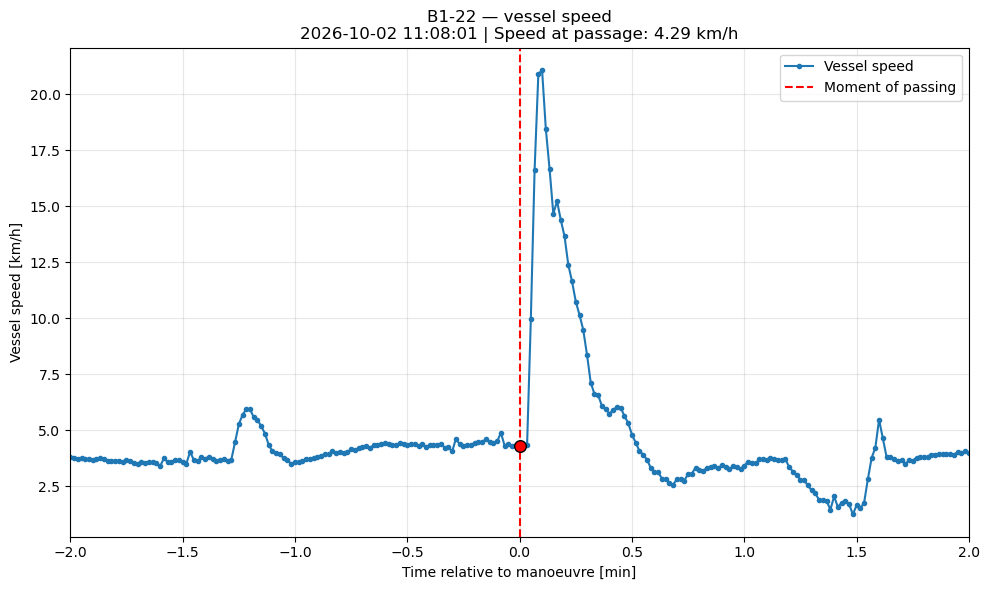

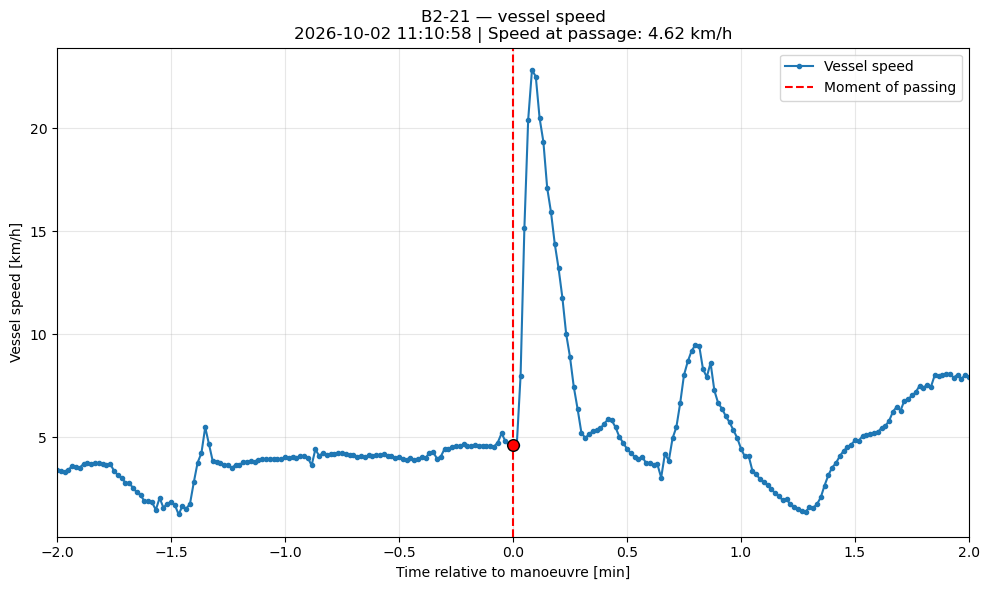

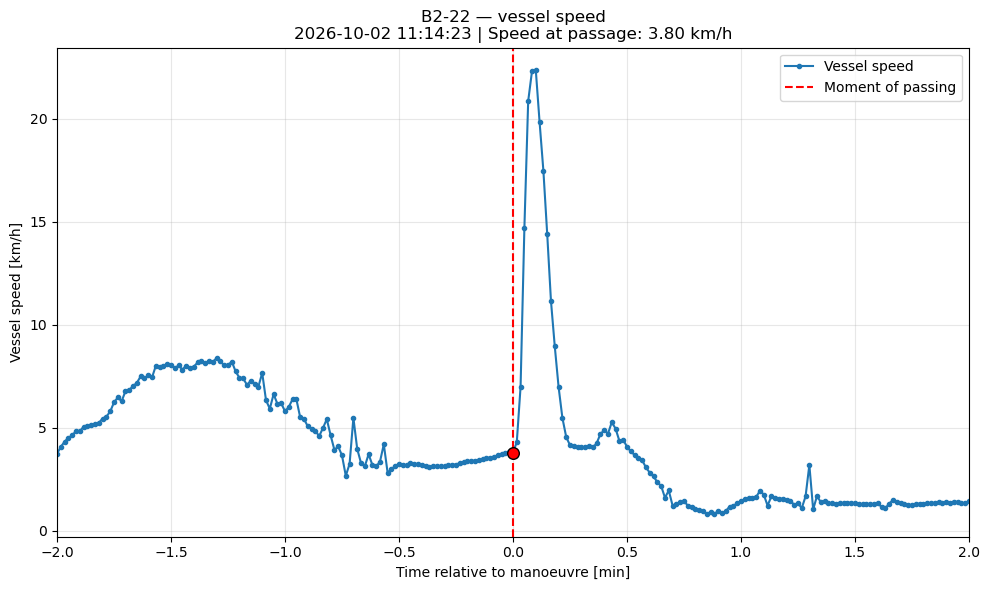

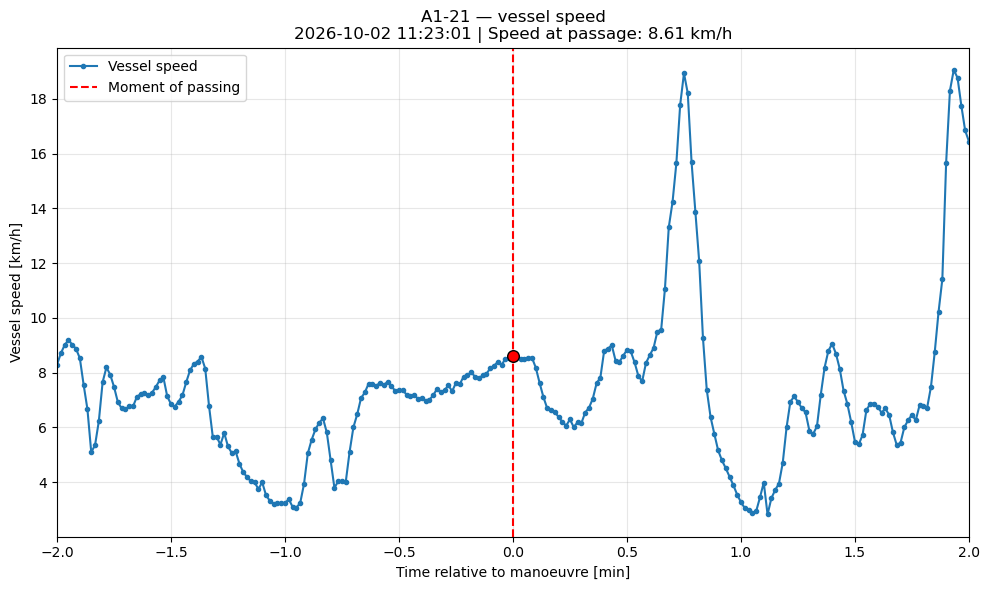

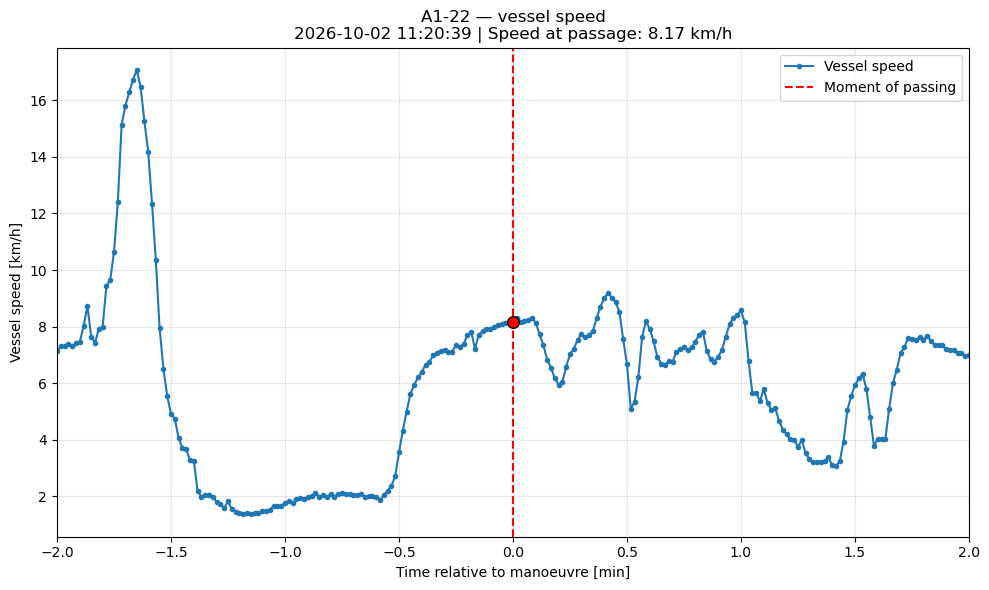

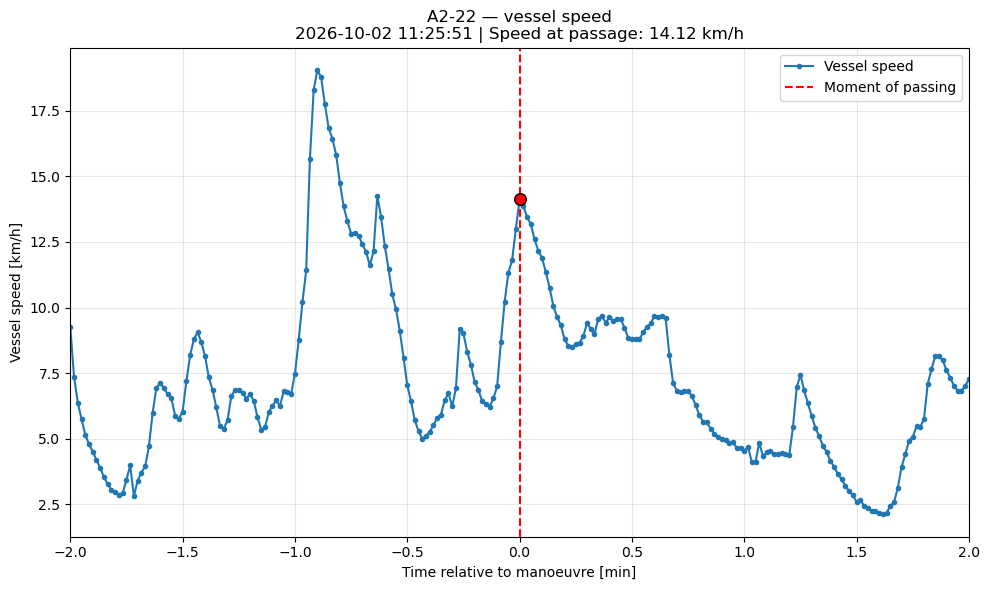

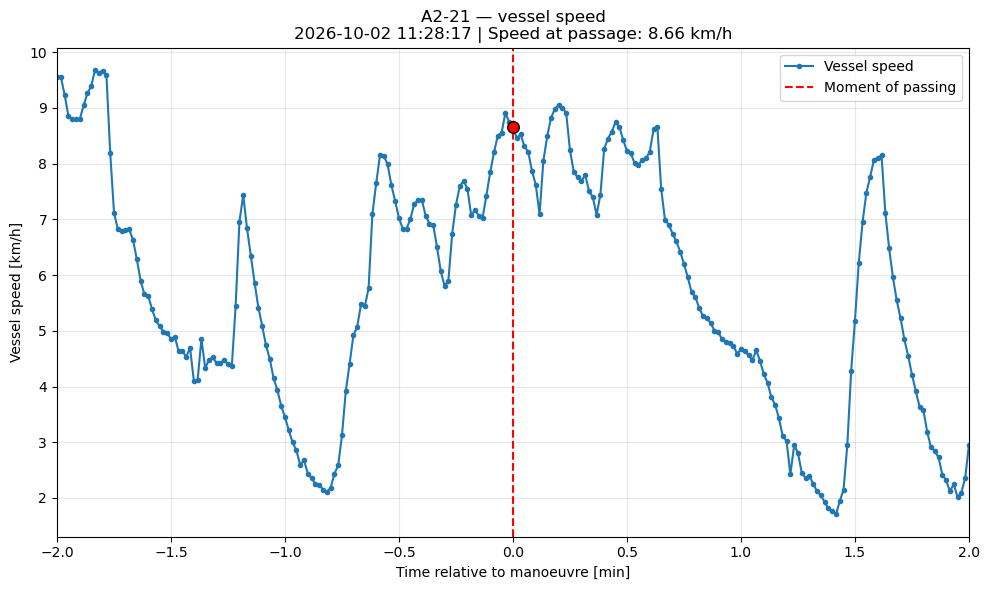

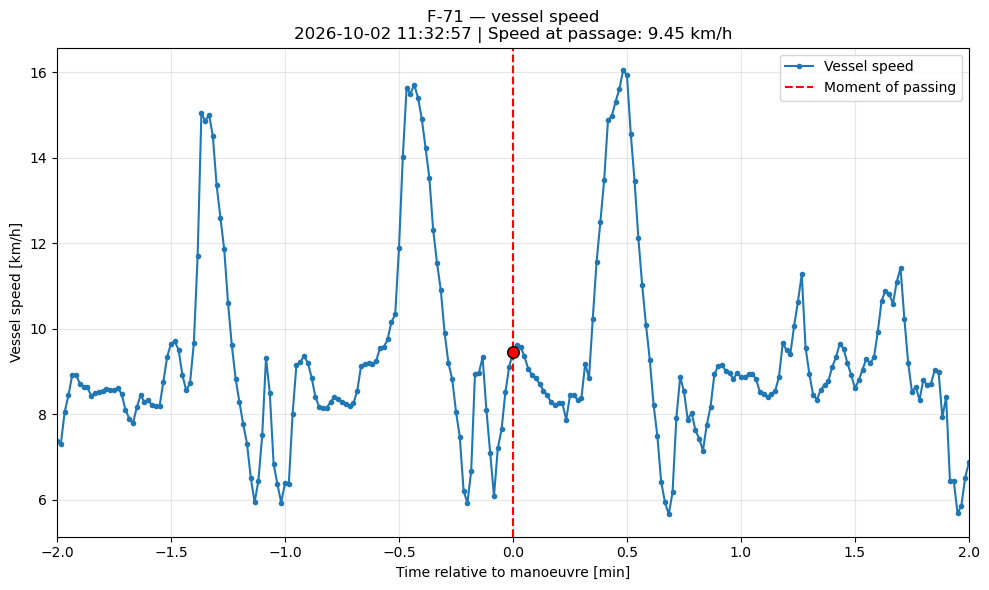

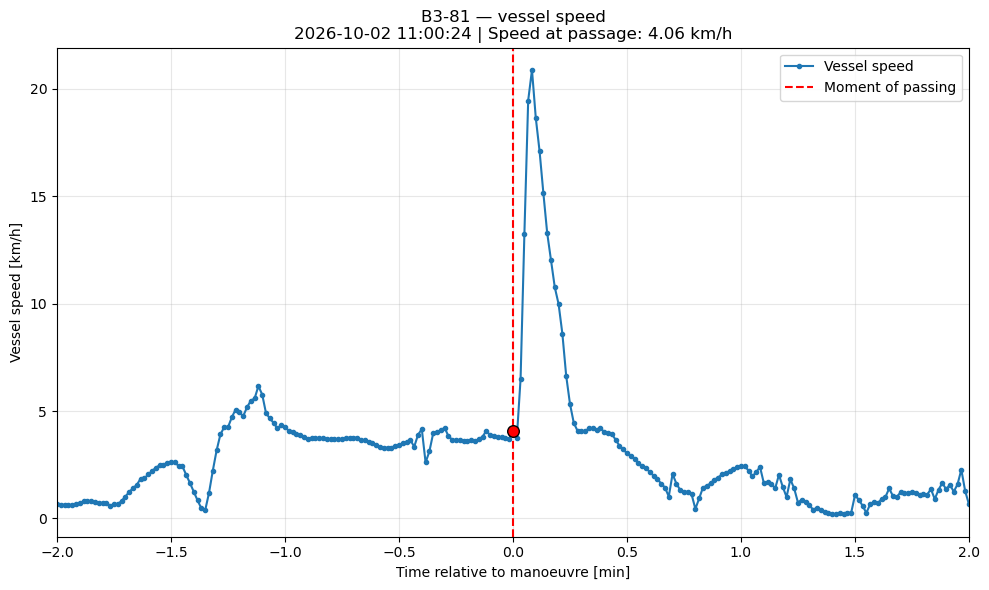

In [20]:
# Plotting vessel speed during each manoeuvre

manoeuvre_date = "2026-10-02"

window_before = pd.Timedelta(minutes=2)
window_after = pd.Timedelta(minutes=2)

for manoeuvre_name, manoeuvre_time in manoeuvres.items():
    manoeuvre_datetime = pd.to_datetime(
        f"{manoeuvre_date} {manoeuvre_time}",
        format="%Y-%m-%d %H:%M:%S",
    )

    start_time = manoeuvre_datetime - window_before
    end_time = manoeuvre_datetime + window_after

    # Use TEST data because this is where vessel speed was calculated
    speed_window = gps[
        (gps["trajectory"] == "GPS_Auto")
        & gps["datetime"].between(start_time, end_time)
    ].copy()

    if speed_window.empty:
        print(f"No TEST speed data found for {manoeuvre_name}")
        continue

    speed_window = speed_window.sort_values("datetime")

    # Remove missing speed values before interpolation
    valid_speed = speed_window.dropna(
        subset=["speed_km_h"]
    ).copy()

    if valid_speed.empty:
        print(f"No valid speed data found for {manoeuvre_name}")
        continue

    # Convert timestamps to seconds for interpolation
    time_seconds = (
        valid_speed["datetime"] - manoeuvre_datetime
    ).dt.total_seconds()

    manoeuvre_time_seconds = 0.0

    # Interpolate only if the manoeuvre time is bracketed
    # by available speed measurements
    if (
        time_seconds.min()
        <= manoeuvre_time_seconds
        <= time_seconds.max()
    ):
        speed_at_manoeuvre = np.interp(
            manoeuvre_time_seconds,
            time_seconds.to_numpy(),
            valid_speed["speed_km_h"].to_numpy(),
        )
        speed_text = f"{speed_at_manoeuvre:.2f} km/h"
    else:
        speed_at_manoeuvre = np.nan
        speed_text = "unavailable"

    # Time relative to the manoeuvre, in minutes
    speed_window["relative_time_min"] = (
        speed_window["datetime"] - manoeuvre_datetime
    ).dt.total_seconds() / 60

    fig, ax = plt.subplots(figsize=(10, 6))

    ax.plot(
        speed_window["relative_time_min"],
        speed_window["speed_km_h"],
        color="tab:blue",
        linewidth=1.5,
        marker="o",
        markersize=3,
        label="Vessel speed",
    )

    # Mark the manoeuvre time
    ax.axvline(
        0,
        color="red",
        linestyle="--",
        linewidth=1.5,
        label="Moment of passing",
    )

    # Mark the interpolated speed at the manoeuvre
    if not np.isnan(speed_at_manoeuvre):
        ax.scatter(
            0,
            speed_at_manoeuvre,
            color="red",
            edgecolor="black",
            s=70,
            zorder=5,
        )

    ax.set_xlim(-2, 2)
    ax.set_xlabel("Time relative to manoeuvre [min]")
    ax.set_ylabel("Vessel speed [km/h]")

    ax.set_title(
        f"{manoeuvre_name} — vessel speed\n"
        f"{manoeuvre_datetime:%Y-%m-%d %H:%M:%S} | "
        f"Speed at passage: {speed_text}"
    )

    ax.grid(True, alpha=0.3)
    ax.legend()

    plt.tight_layout()
    plt.show()

    - GPS000001 is the eastern end of the measurement frame
    - GPS000002 is the western end of the measurement frame
    - GPS000003 is the flagpole at the instruments
    - GPS000004 is the flagpole more in the port
    - GPS000005 is the flagpole more towards the sea

In [ ]:
print(gps_points["easting"], gps_points["northing"])


6143    806486.1892
6144    806485.3477
6145    806484.9354
6146    806485.4415
6147    806483.5200
Name: easting, dtype: float64 6143    2.343121e+06
6144    2.343120e+06
6145    2.343120e+06
6146    2.343117e+06
6147    2.343123e+06
Name: northing, dtype: float64


In [ ]:
#distance port-side flag pole instrument:
easting_distance_port_pole = gps_points["easting"][6145] - gps_points["easting"][6146]
northing_distance_port_pole = gps_points["northing"][6145] - gps_points["northing"][6146]
print(f'distance port-side pole: {easting_distance_port_pole} m')
print(f'distance port-side pole: {northing_distance_port_pole} m')

total_dist_port = np.sqrt(easting_distance_port_pole**2 + northing_distance_port_pole**2)
print(f'total distance port-side pole: {total_dist_port} m')
print()

#distance see-side flag pole instrument:
easting_distance_sea_pole = gps_points["easting"][6145] - gps_points["easting"][6147]
northing_distance_sea_pole = gps_points["northing"][6145] - gps_points["northing"][6147]
print(f'distance sea-side pole: {easting_distance_sea_pole} m')
print(f'distance sea-side pole: {northing_distance_sea_pole} m')

total_dist_sea = np.sqrt(easting_distance_sea_pole**2 + northing_distance_sea_pole**2)
print(f'total distance sea-side pole: {total_dist_sea} m')

distance port-side pole: -0.5060999999986961 m
distance port-side pole: 3.081400000024587 m
total distance port-side pole: 3.1226852499331734 m

distance sea-side pole: 1.4153999999398366 m
distance sea-side pole: -2.488699999637902 m
total distance sea-side pole: 2.863037695879567 m
